# Fake News Detection using Deep Learning and Transfer Learning

## Models
1. BiLSTM — Built from Scratch
2. BERT — Transfer Learning
3. DistilBERT — Transfer Learning
4. RoBERTa — Transfer Learning
5. ALBERT — Transfer Learning

## Workflow
Dataset → EDA → Preprocessing → Model Training
→ Model Comparison → Optimization → Final Evaluation

## STEP 1
Uploading all library and dataset

In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu128
GPU available: True
GPU: Tesla T4


In [ ]:
!pip install -q transformers datasets accelerate evaluate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.7 MB/s eta 0:00:00


In [ ]:
# Importing all library

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings

warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu128
GPU available: True
GPU: Tesla T4


In [ ]:
# Loading the dataset

df = pd.read_csv("/content/FakeNewsNet.csv")

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (23196, 5)

Columns:
['title', 'news_url', 'source_domain', 'tweet_num', 'real']


,title,news_url,source_domain,tweet_num,real
0,Kandi Burruss Explodes Over Rape Accusation on...,http://toofab.com/2017/05/08/real-housewives-a...,toofab.com,42,1
1,People's Choice Awards 2018: The best red carp...,https://www.today.com/style/see-people-s-choic...,www.today.com,0,1
2,Sophia Bush Sends Sweet Birthday Message to 'O...,https://www.etonline.com/news/220806_sophia_bu...,www.etonline.com,63,1
3,Colombian singer Maluma sparks rumours of inap...,https://www.dailymail.co.uk/news/article-33655...,www.dailymail.co.uk,20,1
4,Gossip Girl 10 Years Later: How Upper East Sid...,https://www.zerchoo.com/entertainment/gossip-g...,www.zerchoo.com,38,1


## STEP 2: EDA


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23196 entries, 0 to 23195
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   title          23196 non-null  object
 1   news_url       22866 non-null  object
 2   source_domain  22866 non-null  object
 3   tweet_num      23196 non-null  int64 
 4   real           23196 non-null  int64 
dtypes: int64(2), object(3)
memory usage: 906.2+ KB


In [ ]:
# Missing values
print("Missing values:")
print(df.isnull().sum())

Missing values:
title              0
news_url         330
source_domain    330
tweet_num          0
real               0
dtype: int64


In [ ]:
# Duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 137


In [ ]:
# Lable distributuon and percentage

print(df["real"].value_counts())
print(
    df["real"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

real
1    17441
0     5755
Name: count, dtype: int64
real
1    75.19
0    24.81
Name: proportion, dtype: float64


## STEP 3: VISUALIZING THE CLASSES

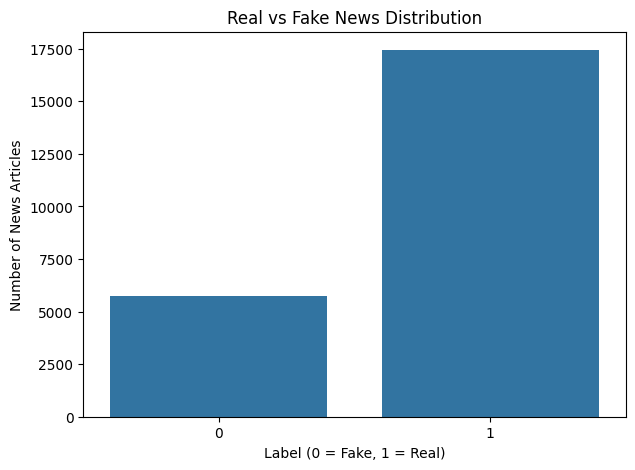

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="real"
)

plt.title("Real vs Fake News Distribution")
plt.xlabel("Label (0 = Fake, 1 = Real)")
plt.ylabel("Number of News Articles")

plt.show()

##STEP 4: Analyzing the patterns

In [ ]:
df["title_length"] = df["title"].fillna("").apply(len)

df["word_count"] = df["title"].fillna("").apply(
    lambda x: len(str(x).split())
)

display(
    df[["title_length", "word_count"]].describe()
)

,title_length,word_count
count,23196.000000,23196.000000
mean,68.303328,11.161192
std,23.287987,3.977693
min,10.000000,1.000000
25%,55.000000,9.000000
50%,68.000000,11.000000
75%,84.000000,14.000000
max,340.000000,53.000000


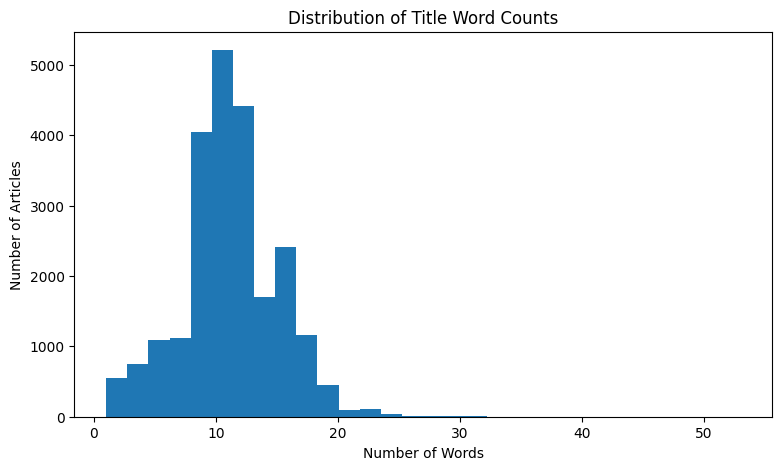

In [ ]:
plt.figure(figsize=(9, 5))

plt.hist(
    df["word_count"],
    bins=30
)

plt.title("Distribution of Title Word Counts")
plt.xlabel("Number of Words")
plt.ylabel("Number of Articles")

plt.show()

##STEP 5: Basic cleaning

In [ ]:
def clean_title(text):
    text = str(text)

    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)

    # Remove HTML tags
    text = re.sub(r"<.*?>", "", text)

    # Remove extra whitespace
    text = re.sub(r"\s+", " ", text)

    return text.strip()

In [ ]:
df["title"] = df["title"].fillna("").apply(clean_title)

In [ ]:
df = df[df["title"].str.len() > 0].reset_index(drop=True)

print("Dataset after cleaning:", df.shape)

Dataset after cleaning: (23196, 7)


##STEP 7: Distributing the data

In [ ]:
X = df["title"]
y = df["real"]

## STEP 8: Train/Validation/Test split

In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [ ]:
print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

Training samples: 18556
Validation samples: 2320
Testing samples: 2320


In [ ]:
print("\nTraining distribution:")
print(y_train.value_counts(normalize=True))

print("\nValidation distribution:")
print(y_val.value_counts(normalize=True))

print("\nTesting distribution:")
print(y_test.value_counts(normalize=True))


Training distribution:
real
1    0.751886
0    0.248114
Name: proportion, dtype: float64

Validation distribution:
real
1    0.752155
0    0.247845
Name: proportion, dtype: float64

Testing distribution:
real
1    0.751724
0    0.248276
Name: proportion, dtype: float64


## Building Models

Model 1 — BiLSTM from Scratch

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from collections import Counter

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

Using device: cuda


In [ ]:
# Build our vocabulary

PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"

MAX_VOCAB_SIZE = 20000
MIN_FREQ = 2

In [ ]:
counter = Counter()

for text in X_train:
    words = str(text).lower().split()
    counter.update(words)

vocab = {
    PAD_TOKEN: 0,
    UNK_TOKEN: 1
}

for word, freq in counter.most_common(MAX_VOCAB_SIZE - 2):
    if freq >= MIN_FREQ:
        vocab[word] = len(vocab)

print("Vocabulary size:", len(vocab))

Vocabulary size: 12118


In [ ]:
# Convert text → numbers

def text_to_sequence(text):
    words = str(text).lower().split()

    sequence = [
        vocab.get(word, vocab[UNK_TOKEN])
        for word in words
    ]

    return sequence

In [ ]:
sample_text = X_train.iloc[0]

print("Original:")
print(sample_text)

print("\nSequence:")
print(text_to_sequence(sample_text))

Original:
HollywoodLife Flips-Flops On John Cena Wanting Children With Nikki Bella

Sequence:
[1985, 1, 8, 109, 595, 3925, 673, 9, 285, 124]


In [ ]:
# Choosing sequence length
MAX_LENGTH = 50

In [ ]:
# Padding and truncating
def pad_sequence(sequence, max_length=MAX_LENGTH):

    if len(sequence) > max_length:
        sequence = sequence[:max_length]

    else:
        sequence = sequence + [vocab[PAD_TOKEN]] * (
            max_length - len(sequence)
        )

    return sequence

In [ ]:
sequence = text_to_sequence(sample_text)

print("Before padding:", len(sequence))

padded = pad_sequence(sequence)

print("After padding:", len(padded))
print(padded)

Before padding: 10
After padding: 50
[1985, 1, 8, 109, 595, 3925, 673, 9, 285, 124, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [ ]:
# Creating PyTorch dataset

class FakeNewsDataset(Dataset):

    def __init__(self, texts, labels):
        self.texts = texts.reset_index(drop=True)
        self.labels = labels.reset_index(drop=True)

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):

        text = self.texts.iloc[index]
        label = self.labels.iloc[index]

        sequence = text_to_sequence(text)
        sequence = pad_sequence(sequence)

        return (
            torch.tensor(sequence, dtype=torch.long),
            torch.tensor(label, dtype=torch.float)
        )

In [ ]:
train_dataset = FakeNewsDataset(
    X_train,
    y_train
)

val_dataset = FakeNewsDataset(
    X_val,
    y_val
)

test_dataset = FakeNewsDataset(
    X_test,
    y_test
)


In [ ]:
# Data loader
BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [ ]:
texts, labels = next(iter(train_loader))

print("Text batch shape:", texts.shape)
print("Label batch shape:", labels.shape)

Text batch shape: torch.Size([64, 50])
Label batch shape: torch.Size([64])


In [ ]:
# Building BiLSTM

class BiLSTMClassifier(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim=128,
        hidden_dim=128,
        num_layers=2,
        dropout=0.3
    ):

        super(BiLSTMClassifier, self).__init__()

        # Embedding layer
        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=0
        )

        # Bidirectional LSTM
        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout if num_layers > 1 else 0
        )

        # Dropout
        self.dropout = nn.Dropout(dropout)

        # Fully connected layer
        self.fc = nn.Linear(
            hidden_dim * 2,
            1
        )

    def forward(self, x):

        # x → [batch_size, sequence_length]
        embedded = self.embedding(x)

        # embedded → [batch, seq_len, embedding_dim]
        output, (hidden, cell) = self.lstm(embedded)

        # Forward and backward final hidden states
        forward_hidden = hidden[-2]
        backward_hidden = hidden[-1]

        # Combine them
        hidden_combined = torch.cat(
            (forward_hidden, backward_hidden),
            dim=1
        )

        hidden_combined = self.dropout(
            hidden_combined
        )

        output = self.fc(
            hidden_combined
        )

        return output.squeeze(1)

In [ ]:
# Creating the model

model = BiLSTMClassifier(
    vocab_size=len(vocab),
    embedding_dim=128,
    hidden_dim=128,
    num_layers=2,
    dropout=0.3
)

model = model.to(device)

print(model)

BiLSTMClassifier(
  (embedding): Embedding(12118, 128, padding_idx=0)
  (lstm): LSTM(128, 128, num_layers=2, batch_first=True, dropout=0.3, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=256, out_features=1, bias=True)
)


In [ ]:
# Loss Function

criterion = nn.BCEWithLogitsLoss()

In [ ]:
# Optimizer

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [ ]:
# Training function

def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer
):

    model.train()

    total_loss = 0

    all_predictions = []
    all_labels = []

    for texts, labels in loader:

        texts = texts.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(texts)

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

        probabilities = torch.sigmoid(outputs)

        predictions = (
            probabilities >= 0.5
        ).long()

        all_predictions.extend(
            predictions.detach().cpu().numpy()
        )

        all_labels.extend(
            labels.cpu().numpy()
        )

    avg_loss = total_loss / len(loader)

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    f1 = f1_score(
        all_labels,
        all_predictions
    )

    return avg_loss, accuracy, f1

In [ ]:
# Validation Function
def evaluate(
    model,
    loader,
    criterion
):

    model.eval()

    total_loss = 0

    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for texts, labels in loader:

            texts = texts.to(device)
            labels = labels.to(device)

            outputs = model(texts)

            loss = criterion(
                outputs,
                labels
            )

            total_loss += loss.item()

            probabilities = torch.sigmoid(outputs)

            predictions = (
                probabilities >= 0.5
            ).long()

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    avg_loss = total_loss / len(loader)

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    precision = precision_score(
        all_labels,
        all_predictions,
        zero_division=0
    )

    recall = recall_score(
        all_labels,
        all_predictions,
        zero_division=0
    )

    f1 = f1_score(
        all_labels,
        all_predictions,
        zero_division=0
    )

    return (
        avg_loss,
        accuracy,
        precision,
        recall,
        f1,
        all_labels,
        all_predictions
    )

In [ ]:
EPOCHS = 5

best_val_f1 = 0.0
history = {
    "train_loss": [],
    "train_f1": [],
    "val_loss": [],
    "val_f1": []
}

for epoch in range(EPOCHS):

    train_loss, train_acc, train_f1 = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer
    )

    (
        val_loss,
        val_acc,
        val_precision,
        val_recall,
        val_f1,
        _,
        _
    ) = evaluate(
        model,
        val_loader,
        criterion
    )

    history["train_loss"].append(train_loss)
    history["train_f1"].append(train_f1)
    history["val_loss"].append(val_loss)
    history["val_f1"].append(val_f1)

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Train F1: {train_f1:.4f}"
    )

    print(
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val Precision: {val_precision:.4f} | "
        f"Val Recall: {val_recall:.4f} | "
        f"Val F1: {val_f1:.4f}"
    )

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1

        torch.save(
            model.state_dict(),
            "best_bilstm_model.pth"
        )

        print("Best model saved!")

print("\nBest Validation F1:", best_val_f1)


Epoch 1/5
Train Loss: 0.4739 | Train Acc: 0.7918 | Train F1: 0.8735
Val Loss: 0.4269 | Val Acc: 0.8233 | Val Precision: 0.8421 | Val Recall: 0.9415 | Val F1: 0.8891
Best model saved!

Epoch 2/5
Train Loss: 0.3708 | Train Acc: 0.8442 | Train F1: 0.9007
Val Loss: 0.3825 | Val Acc: 0.8444 | Val Precision: 0.8642 | Val Recall: 0.9410 | Val F1: 0.9010
Best model saved!

Epoch 3/5
Train Loss: 0.2958 | Train Acc: 0.8771 | Train F1: 0.9203
Val Loss: 0.4050 | Val Acc: 0.8345 | Val Precision: 0.8700 | Val Recall: 0.9169 | Val F1: 0.8929

Epoch 4/5
Train Loss: 0.2210 | Train Acc: 0.9121 | Train F1: 0.9422
Val Loss: 0.4344 | Val Acc: 0.8388 | Val Precision: 0.8687 | Val Recall: 0.9255 | Val F1: 0.8962

Epoch 5/5
Train Loss: 0.1538 | Train Acc: 0.9403 | Train F1: 0.9604
Val Loss: 0.5263 | Val Acc: 0.8310 | Val Precision: 0.8651 | Val Recall: 0.9186 | Val F1: 0.8911

Best Validation F1: 0.900960219478738


In [ ]:
# Loading the best BiLSTM Model

# Load the best BiLSTM model
model.load_state_dict(
    torch.load("best_bilstm_model.pth", map_location=device)
)

model = model.to(device)

# Evaluate on test set
(
    test_loss,
    test_acc,
    test_precision,
    test_recall,
    test_f1,
    test_labels,
    test_predictions
) = evaluate(
    model,
    test_loader,
    criterion
)

print("===== BiLSTM TEST RESULTS =====")
print(f"Test Loss:      {test_loss:.4f}")
print(f"Test Accuracy:  {test_acc:.4f}")
print(f"Test Precision: {test_precision:.4f}")
print(f"Test Recall:    {test_recall:.4f}")
print(f"Test F1:        {test_f1:.4f}")

===== BiLSTM TEST RESULTS =====
Test Loss:      0.3967
Test Accuracy:  0.8280
Test Precision: 0.8590
Test Recall:    0.9226
Test F1:        0.8897


In [ ]:
# Classification report

print("\n===== CLASSIFICATION REPORT =====")

print(
    classification_report(
        test_labels,
        test_predictions,
        target_names=["Fake", "Real"],
        digits=4
    )
)


===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

        Fake     0.6980    0.5417    0.6100       576
        Real     0.8590    0.9226    0.8897      1744

    accuracy                         0.8280      2320
   macro avg     0.7785    0.7321    0.7498      2320
weighted avg     0.8191    0.8280    0.8202      2320



In [ ]:
# Confusion matrix

print("\n===== CONFUSION MATRIX =====")

cm = confusion_matrix(
    test_labels,
    test_predictions
)

print(cm)


===== CONFUSION MATRIX =====
[[ 312  264]
 [ 135 1609]]


In [ ]:
history

{'train_loss': [0.47392995018383555,
  0.37075411826372145,
  0.2958363250925623,
  0.2210448868572712,
  0.15383847783608684],
 'train_f1': [0.873518821603928,
  0.9007381974248927,
  0.9202574146614437,
  0.9421850644749894,
  0.9604229175596514],
 'val_loss': [0.42686786361642787,
  0.3825027576169452,
  0.405006020455747,
  0.4344494491815567,
  0.5263345362366857],
 'val_f1': [0.8890692640692641,
  0.900960219478738,
  0.8928571428571429,
  0.8962264150943396,
  0.8910505836575876]}

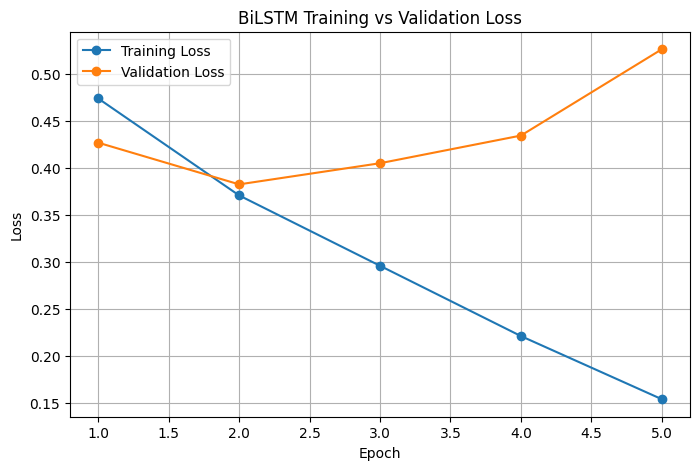

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)

# Loss graph
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("BiLSTM Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

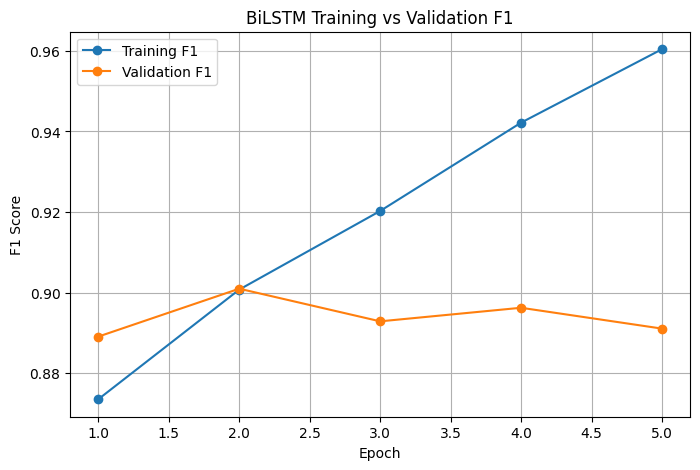

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["train_f1"],
    marker="o",
    label="Training F1"
)

plt.plot(
    epochs,
    history["val_f1"],
    marker="o",
    label="Validation F1"
)

plt.xlabel("Epoch")
plt.ylabel("F1 Score")
plt.title("BiLSTM Training vs Validation F1")
plt.legend()
plt.grid(True)

plt.show()

Model 2 -- BERT

In [ ]:
!pip install -q transformers accelerate

In [ ]:
import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Using device:", device)

Using device: cuda


In [ ]:
# Loading BERT tokenizer

MODEL_NAME = "bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Tokenizer loaded!")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tokenizer loaded!


In [ ]:
# Creating BERT Dataset

class BERTDataset(Dataset):

    def __init__(self, texts, labels, tokenizer, max_length=64):

        self.texts = texts.reset_index(drop=True)
        self.labels = labels.reset_index(drop=True)

        self.encodings = tokenizer(
            self.texts.tolist(),
            truncation=True,
            padding="max_length",
            max_length=max_length
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):

        item = {
            key: torch.tensor(value[index])
            for key, value in self.encodings.items()
        }

        item["labels"] = torch.tensor(
            self.labels.iloc[index],
            dtype=torch.long
        )

        return item

In [ ]:
# Creating dataset

bert_train_dataset = BERTDataset(
    X_train,
    y_train,
    tokenizer
)

bert_val_dataset = BERTDataset(
    X_val,
    y_val,
    tokenizer
)

bert_test_dataset = BERTDataset(
    X_test,
    y_test,
    tokenizer
)

print("Datasets created!")

Datasets created!


In [ ]:
# Data loaders

BERT_BATCH_SIZE = 16

bert_train_loader = DataLoader(
    bert_train_dataset,
    batch_size=BERT_BATCH_SIZE,
    shuffle=True
)

bert_val_loader = DataLoader(
    bert_val_dataset,
    batch_size=BERT_BATCH_SIZE,
    shuffle=False
)

bert_test_loader = DataLoader(
    bert_test_dataset,
    batch_size=BERT_BATCH_SIZE,
    shuffle=False
)

print("DataLoaders created!")

DataLoaders created!


In [ ]:
# Loading BERT

bert_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2
)

bert_model = bert_model.to(device)

print("BERT loaded!")

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT loaded!


In [ ]:
# Optimizers

bert_optimizer = torch.optim.AdamW(
    bert_model.parameters(),
    lr=2e-5
)

In [ ]:
bert_criterion = nn.CrossEntropyLoss()

In [ ]:
# Training Function

def train_bert_one_epoch(
    model,
    loader,
    optimizer
):

    model.train()

    total_loss = 0
    all_predictions = []
    all_labels = []

    for batch in loader:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad()

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss
        logits = outputs.logits

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        predictions = torch.argmax(
            logits,
            dim=1
        )

        all_predictions.extend(
            predictions.detach().cpu().numpy()
        )

        all_labels.extend(
            labels.detach().cpu().numpy()
        )

    avg_loss = total_loss / len(loader)

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    f1 = f1_score(
        all_labels,
        all_predictions
    )

    return avg_loss, accuracy, f1

In [ ]:
# Evaluation Function

def evaluate_bert(
    model,
    loader
):

    model.eval()

    total_loss = 0
    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for batch in loader:

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            loss = outputs.loss
            logits = outputs.logits

            total_loss += loss.item()

            predictions = torch.argmax(
                logits,
                dim=1
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    avg_loss = total_loss / len(loader)

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    precision = precision_score(
        all_labels,
        all_predictions,
        zero_division=0
    )

    recall = recall_score(
        all_labels,
        all_predictions,
        zero_division=0
    )

    f1 = f1_score(
        all_labels,
        all_predictions,
        zero_division=0
    )

    return (
        avg_loss,
        accuracy,
        precision,
        recall,
        f1,
        all_labels,
        all_predictions
    )

In [ ]:
EPOCHS = 3

best_bert_val_f1 = 0.0

bert_history = {
    "train_loss": [],
    "train_f1": [],
    "val_loss": [],
    "val_f1": []
}

for epoch in range(EPOCHS):

    train_loss, train_acc, train_f1 = train_bert_one_epoch(
        bert_model,
        bert_train_loader,
        bert_optimizer
    )

    (
        val_loss,
        val_acc,
        val_precision,
        val_recall,
        val_f1,
        _,
        _
    ) = evaluate_bert(
        bert_model,
        bert_val_loader
    )

    bert_history["train_loss"].append(train_loss)
    bert_history["train_f1"].append(train_f1)
    bert_history["val_loss"].append(val_loss)
    bert_history["val_f1"].append(val_f1)

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Train F1: {train_f1:.4f}"
    )

    print(
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val Precision: {val_precision:.4f} | "
        f"Val Recall: {val_recall:.4f} | "
        f"Val F1: {val_f1:.4f}"
    )

    if val_f1 > best_bert_val_f1:

        best_bert_val_f1 = val_f1

        torch.save(
            bert_model.state_dict(),
            "best_bert_model.pth"
        )

        print("Best BERT model saved!")

print("\nBest BERT Validation F1:", best_bert_val_f1)


Epoch 1/3
Train Loss: 0.4034 | Train Acc: 0.8272 | Train F1: 0.8915
Val Loss: 0.3695 | Val Acc: 0.8440 | Val Precision: 0.9158 | Val Recall: 0.8728 | Val F1: 0.8938
Best BERT model saved!

Epoch 2/3
Train Loss: 0.2783 | Train Acc: 0.8873 | Train F1: 0.9268
Val Loss: 0.3695 | Val Acc: 0.8509 | Val Precision: 0.9151 | Val Recall: 0.8837 | Val F1: 0.8991
Best BERT model saved!

Epoch 3/3
Train Loss: 0.1736 | Train Acc: 0.9332 | Train F1: 0.9559
Val Loss: 0.4021 | Val Acc: 0.8539 | Val Precision: 0.9017 | Val Recall: 0.9043 | Val F1: 0.9030
Best BERT model saved!

Best BERT Validation F1: 0.9030042918454936


In [ ]:
# BERT test evaluation

# Load best BERT checkpoint
bert_model.load_state_dict(
    torch.load(
        "best_bert_model.pth",
        map_location=device
    )
)

bert_model = bert_model.to(device)

# Test evaluation
(
    bert_test_loss,
    bert_test_acc,
    bert_test_precision,
    bert_test_recall,
    bert_test_f1,
    bert_test_labels,
    bert_test_predictions
) = evaluate_bert(
    bert_model,
    bert_test_loader
)

print("===== BERT TEST RESULTS =====")
print(f"Test Loss:      {bert_test_loss:.4f}")
print(f"Test Accuracy:  {bert_test_acc:.4f}")
print(f"Test Precision: {bert_test_precision:.4f}")
print(f"Test Recall:    {bert_test_recall:.4f}")
print(f"Test F1:        {bert_test_f1:.4f}")

===== BERT TEST RESULTS =====
Test Loss:      0.4201
Test Accuracy:  0.8461
Test Precision: 0.8961
Test Recall:    0.8997
Test F1:        0.8979


In [ ]:
print("\n===== BERT CLASSIFICATION REPORT =====")

print(
    classification_report(
        bert_test_labels,
        bert_test_predictions,
        target_names=["Fake", "Real"],
        digits=4
    )
)


===== BERT CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

        Fake     0.6924    0.6840    0.6882       576
        Real     0.8961    0.8997    0.8979      1744

    accuracy                         0.8461      2320
   macro avg     0.7943    0.7918    0.7930      2320
weighted avg     0.8455    0.8461    0.8458      2320



In [ ]:
print("\n===== BERT CONFUSION MATRIX =====")

bert_cm = confusion_matrix(
    bert_test_labels,
    bert_test_predictions
)

print(bert_cm)


===== BERT CONFUSION MATRIX =====
[[ 394  182]
 [ 175 1569]]


Model 3 — DistilBERT

In [ ]:
# Loading DistilBERT

DISTILBERT_MODEL_NAME = "distilbert-base-uncased"

distilbert_tokenizer = AutoTokenizer.from_pretrained(
    DISTILBERT_MODEL_NAME
)

print("DistilBERT tokenizer loaded!")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

DistilBERT tokenizer loaded!


In [ ]:
# Creating Dataset

distilbert_train_dataset = BERTDataset(
    X_train,
    y_train,
    distilbert_tokenizer
)

distilbert_val_dataset = BERTDataset(
    X_val,
    y_val,
    distilbert_tokenizer
)

distilbert_test_dataset = BERTDataset(
    X_test,
    y_test,
    distilbert_tokenizer
)

print("DistilBERT datasets created!")

DistilBERT datasets created!


In [ ]:
# Data Loaders

DISTILBERT_BATCH_SIZE = 16

distilbert_train_loader = DataLoader(
    distilbert_train_dataset,
    batch_size=DISTILBERT_BATCH_SIZE,
    shuffle=True
)

distilbert_val_loader = DataLoader(
    distilbert_val_dataset,
    batch_size=DISTILBERT_BATCH_SIZE,
    shuffle=False
)

distilbert_test_loader = DataLoader(
    distilbert_test_dataset,
    batch_size=DISTILBERT_BATCH_SIZE,
    shuffle=False
)

In [ ]:
# Loading Model

distilbert_model = AutoModelForSequenceClassification.from_pretrained(
    DISTILBERT_MODEL_NAME,
    num_labels=2
)

distilbert_model = distilbert_model.to(device)

print("DistilBERT loaded!")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBERT loaded!


In [ ]:
# Optimizer

distilbert_optimizer = torch.optim.AdamW(
    distilbert_model.parameters(),
    lr=2e-5
)

In [ ]:
# training

EPOCHS = 3

best_distilbert_val_f1 = 0.0

distilbert_history = {
    "train_loss": [],
    "train_f1": [],
    "val_loss": [],
    "val_f1": []
}

for epoch in range(EPOCHS):

    train_loss, train_acc, train_f1 = train_bert_one_epoch(
        distilbert_model,
        distilbert_train_loader,
        distilbert_optimizer
    )

    (
        val_loss,
        val_acc,
        val_precision,
        val_recall,
        val_f1,
        _,
        _
    ) = evaluate_bert(
        distilbert_model,
        distilbert_val_loader
    )

    distilbert_history["train_loss"].append(train_loss)
    distilbert_history["train_f1"].append(train_f1)
    distilbert_history["val_loss"].append(val_loss)
    distilbert_history["val_f1"].append(val_f1)

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Train F1: {train_f1:.4f}"
    )

    print(
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val Precision: {val_precision:.4f} | "
        f"Val Recall: {val_recall:.4f} | "
        f"Val F1: {val_f1:.4f}"
    )

    if val_f1 > best_distilbert_val_f1:

        best_distilbert_val_f1 = val_f1

        torch.save(
            distilbert_model.state_dict(),
            "best_distilbert_model.pth"
        )

        print("Best DistilBERT model saved!")

print(
    "\nBest DistilBERT Validation F1:",
    best_distilbert_val_f1
)


Epoch 1/3
Train Loss: 0.3903 | Train Acc: 0.8343 | Train F1: 0.8951
Val Loss: 0.3463 | Val Acc: 0.8526 | Val Precision: 0.8948 | Val Recall: 0.9112 | Val F1: 0.9029
Best DistilBERT model saved!

Epoch 2/3
Train Loss: 0.2666 | Train Acc: 0.8957 | Train F1: 0.9322
Val Loss: 0.3490 | Val Acc: 0.8629 | Val Precision: 0.8726 | Val Recall: 0.9576 | Val F1: 0.9131
Best DistilBERT model saved!

Epoch 3/3
Train Loss: 0.1684 | Train Acc: 0.9347 | Train F1: 0.9570
Val Loss: 0.4143 | Val Acc: 0.8379 | Val Precision: 0.9151 | Val Recall: 0.8648 | Val F1: 0.8892

Best DistilBERT Validation F1: 0.9131147540983606


In [ ]:
# Evaluating on test set

# Load best DistilBERT checkpoint
distilbert_model.load_state_dict(
    torch.load(
        "best_distilbert_model.pth",
        map_location=device
    )
)

distilbert_model = distilbert_model.to(device)

# Test evaluation
(
    distilbert_test_loss,
    distilbert_test_acc,
    distilbert_test_precision,
    distilbert_test_recall,
    distilbert_test_f1,
    distilbert_test_labels,
    distilbert_test_predictions
) = evaluate_bert(
    distilbert_model,
    distilbert_test_loader
)

print("===== DISTILBERT TEST RESULTS =====")

print(f"Test Loss:      {distilbert_test_loss:.4f}")
print(f"Test Accuracy:  {distilbert_test_acc:.4f}")
print(f"Test Precision: {distilbert_test_precision:.4f}")
print(f"Test Recall:    {distilbert_test_recall:.4f}")
print(f"Test F1:        {distilbert_test_f1:.4f}")

===== DISTILBERT TEST RESULTS =====
Test Loss:      0.3502
Test Accuracy:  0.8690
Test Precision: 0.8766
Test Recall:    0.9610
Test F1:        0.9168


In [ ]:
print("\n===== DISTILBERT CLASSIFICATION REPORT =====")

print(
    classification_report(
        distilbert_test_labels,
        distilbert_test_predictions,
        target_names=["Fake", "Real"],
        digits=4
    )
)


===== DISTILBERT CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

        Fake     0.8333    0.5903    0.6911       576
        Real     0.8766    0.9610    0.9168      1744

    accuracy                         0.8690      2320
   macro avg     0.8550    0.7756    0.8040      2320
weighted avg     0.8658    0.8690    0.8608      2320



In [ ]:
print("\n===== DISTILBERT CONFUSION MATRIX =====")

distilbert_cm = confusion_matrix(
    distilbert_test_labels,
    distilbert_test_predictions
)

print(distilbert_cm)


===== DISTILBERT CONFUSION MATRIX =====
[[ 340  236]
 [  68 1676]]


Model 4: RoBERTa

In [ ]:
ROBERTA_MODEL_NAME = "roberta-base"

In [ ]:
# Tokenizer

ROBERTA_MODEL_NAME = "roberta-base"

roberta_tokenizer = AutoTokenizer.from_pretrained(
    ROBERTA_MODEL_NAME
)

print("RoBERTa tokenizer loaded!")

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

RoBERTa tokenizer loaded!


In [ ]:
# Dataset

roberta_train_dataset = BERTDataset(
    X_train,
    y_train,
    roberta_tokenizer
)

roberta_val_dataset = BERTDataset(
    X_val,
    y_val,
    roberta_tokenizer
)

roberta_test_dataset = BERTDataset(
    X_test,
    y_test,
    roberta_tokenizer
)

In [ ]:
# Data loader

ROBERTA_BATCH_SIZE = 16

roberta_train_loader = DataLoader(
    roberta_train_dataset,
    batch_size=ROBERTA_BATCH_SIZE,
    shuffle=True
)

roberta_val_loader = DataLoader(
    roberta_val_dataset,
    batch_size=ROBERTA_BATCH_SIZE,
    shuffle=False
)

roberta_test_loader = DataLoader(
    roberta_test_dataset,
    batch_size=ROBERTA_BATCH_SIZE,
    shuffle=False
)

In [ ]:
# Loading RoBERTa

roberta_model = AutoModelForSequenceClassification.from_pretrained(
    ROBERTA_MODEL_NAME,
    num_labels=2
).to(device)

print("RoBERTa loaded!")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


RoBERTa loaded!


In [ ]:
roberta_optimizer = torch.optim.AdamW(
    roberta_model.parameters(),
    lr=2e-5
)

In [ ]:
# Testing

EPOCHS = 3

best_roberta_val_f1 = 0.0

roberta_history = {
    "train_loss": [],
    "train_f1": [],
    "val_loss": [],
    "val_f1": []
}

for epoch in range(EPOCHS):

    train_loss, train_acc, train_f1 = train_bert_one_epoch(
        roberta_model,
        roberta_train_loader,
        roberta_optimizer
    )

    (
        val_loss,
        val_acc,
        val_precision,
        val_recall,
        val_f1,
        _,
        _
    ) = evaluate_bert(
        roberta_model,
        roberta_val_loader
    )

    roberta_history["train_loss"].append(train_loss)
    roberta_history["train_f1"].append(train_f1)
    roberta_history["val_loss"].append(val_loss)
    roberta_history["val_f1"].append(val_f1)

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Train F1: {train_f1:.4f}"
    )

    print(
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val Precision: {val_precision:.4f} | "
        f"Val Recall: {val_recall:.4f} | "
        f"Val F1: {val_f1:.4f}"
    )

    if val_f1 > best_roberta_val_f1:

        best_roberta_val_f1 = val_f1

        torch.save(
            roberta_model.state_dict(),
            "best_roberta_model.pth"
        )

        print("Best RoBERTa model saved!")

print(
    "\nBest RoBERTa Validation F1:",
    best_roberta_val_f1
)


Epoch 1/3
Train Loss: 0.3988 | Train Acc: 0.8310 | Train F1: 0.8937
Val Loss: 0.3345 | Val Acc: 0.8599 | Val Precision: 0.8785 | Val Recall: 0.9444 | Val F1: 0.9102
Best RoBERTa model saved!

Epoch 2/3
Train Loss: 0.3037 | Train Acc: 0.8757 | Train F1: 0.9197
Val Loss: 0.3355 | Val Acc: 0.8694 | Val Precision: 0.8970 | Val Recall: 0.9335 | Val F1: 0.9149
Best RoBERTa model saved!

Epoch 3/3
Train Loss: 0.2426 | Train Acc: 0.9036 | Train F1: 0.9372
Val Loss: 0.3305 | Val Acc: 0.8711 | Val Precision: 0.8870 | Val Recall: 0.9496 | Val F1: 0.9172
Best RoBERTa model saved!

Best RoBERTa Validation F1: 0.9172432881262109


In [ ]:
# Evaluation test

# Load best RoBERTa checkpoint
roberta_model.load_state_dict(
    torch.load(
        "best_roberta_model.pth",
        map_location=device
    )
)

roberta_model = roberta_model.to(device)

# Test evaluation
(
    roberta_test_loss,
    roberta_test_acc,
    roberta_test_precision,
    roberta_test_recall,
    roberta_test_f1,
    roberta_test_labels,
    roberta_test_predictions
) = evaluate_bert(
    roberta_model,
    roberta_test_loader
)

print("===== ROBERTA TEST RESULTS =====")

print(f"Test Loss:      {roberta_test_loss:.4f}")
print(f"Test Accuracy:  {roberta_test_acc:.4f}")
print(f"Test Precision: {roberta_test_precision:.4f}")
print(f"Test Recall:    {roberta_test_recall:.4f}")
print(f"Test F1:        {roberta_test_f1:.4f}")

===== ROBERTA TEST RESULTS =====
Test Loss:      0.3449
Test Accuracy:  0.8672
Test Precision: 0.8860
Test Recall:    0.9450
Test F1:        0.9145


In [ ]:
print("\n===== ROBERTA CLASSIFICATION REPORT =====")

print(
    classification_report(
        roberta_test_labels,
        roberta_test_predictions,
        target_names=["Fake", "Real"],
        digits=4
    )
)


===== ROBERTA CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

        Fake     0.7913    0.6319    0.7027       576
        Real     0.8860    0.9450    0.9145      1744

    accuracy                         0.8672      2320
   macro avg     0.8387    0.7884    0.8086      2320
weighted avg     0.8625    0.8672    0.8619      2320



In [ ]:
print("\n===== ROBERTA CONFUSION MATRIX =====")

roberta_cm = confusion_matrix(
    roberta_test_labels,
    roberta_test_predictions
)

print(roberta_cm)


===== ROBERTA CONFUSION MATRIX =====
[[ 364  212]
 [  96 1648]]


Model5 : ALBERT

In [ ]:
ALBERT_MODEL_NAME = "albert-base-v2"

In [ ]:
# Tokenizer

albert_tokenizer = AutoTokenizer.from_pretrained(
    ALBERT_MODEL_NAME
)

print("ALBERT tokenizer loaded!")

config.json:   0%|          | 0.00/684 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/760k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.31M [00:00<?, ?B/s]

ALBERT tokenizer loaded!


In [ ]:
# Dataset

albert_train_dataset = BERTDataset(
    X_train,
    y_train,
    albert_tokenizer
)

albert_val_dataset = BERTDataset(
    X_val,
    y_val,
    albert_tokenizer
)

albert_test_dataset = BERTDataset(
    X_test,
    y_test,
    albert_tokenizer
)

In [ ]:
# Dataloaders

ALBERT_BATCH_SIZE = 16

albert_train_loader = DataLoader(
    albert_train_dataset,
    batch_size=ALBERT_BATCH_SIZE,
    shuffle=True
)

albert_val_loader = DataLoader(
    albert_val_dataset,
    batch_size=ALBERT_BATCH_SIZE,
    shuffle=False
)

albert_test_loader = DataLoader(
    albert_test_dataset,
    batch_size=ALBERT_BATCH_SIZE,
    shuffle=False
)

In [ ]:
# Loading ALBERT

albert_model = AutoModelForSequenceClassification.from_pretrained(
    ALBERT_MODEL_NAME,
    num_labels=2
).to(device)

print("ALBERT loaded!")

Loading weights:   0%|          | 0/25 [00:00<?, ?it/s]

[transformers] AlbertForSequenceClassification LOAD REPORT from: albert-base-v2
Key                          | Status     | 
-----------------------------+------------+-
predictions.dense.weight     | UNEXPECTED | 
predictions.LayerNorm.bias   | UNEXPECTED | 
predictions.dense.bias       | UNEXPECTED | 
predictions.bias             | UNEXPECTED | 
predictions.LayerNorm.weight | UNEXPECTED | 
predictions.decoder.bias     | UNEXPECTED | 
classifier.bias              | MISSING    | 
classifier.weight            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


ALBERT loaded!


In [ ]:
# Optimizer

albert_optimizer = torch.optim.AdamW(
    albert_model.parameters(),
    lr=2e-5
)

In [ ]:
EPOCHS = 3

best_albert_val_f1 = 0.0

albert_history = {
    "train_loss": [],
    "train_f1": [],
    "val_loss": [],
    "val_f1": []
}

for epoch in range(EPOCHS):

    train_loss, train_acc, train_f1 = train_bert_one_epoch(
        albert_model,
        albert_train_loader,
        albert_optimizer
    )

    (
        val_loss,
        val_acc,
        val_precision,
        val_recall,
        val_f1,
        _,
        _
    ) = evaluate_bert(
        albert_model,
        albert_val_loader
    )

    albert_history["train_loss"].append(train_loss)
    albert_history["train_f1"].append(train_f1)
    albert_history["val_loss"].append(val_loss)
    albert_history["val_f1"].append(val_f1)

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Train F1: {train_f1:.4f}"
    )

    print(
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val Precision: {val_precision:.4f} | "
        f"Val Recall: {val_recall:.4f} | "
        f"Val F1: {val_f1:.4f}"
    )

    if val_f1 > best_albert_val_f1:

        best_albert_val_f1 = val_f1

        torch.save(
            albert_model.state_dict(),
            "best_albert_model.pth"
        )

        print("Best ALBERT model saved!")

print(
    "\nBest ALBERT Validation F1:",
    best_albert_val_f1
)


Epoch 1/3
Train Loss: 0.4494 | Train Acc: 0.8033 | Train F1: 0.8778
Val Loss: 0.3898 | Val Acc: 0.8366 | Val Precision: 0.8467 | Val Recall: 0.9559 | Val F1: 0.8980
Best ALBERT model saved!

Epoch 2/3
Train Loss: 0.3670 | Train Acc: 0.8469 | Train F1: 0.9024
Val Loss: 0.3698 | Val Acc: 0.8457 | Val Precision: 0.8431 | Val Recall: 0.9765 | Val F1: 0.9049
Best ALBERT model saved!

Epoch 3/3
Train Loss: 0.3089 | Train Acc: 0.8739 | Train F1: 0.9185
Val Loss: 0.3522 | Val Acc: 0.8500 | Val Precision: 0.8857 | Val Recall: 0.9192 | Val F1: 0.9021

Best ALBERT Validation F1: 0.9049389272437599


In [ ]:
# Evaluation test

# Load best ALBERT checkpoint
albert_model.load_state_dict(
    torch.load(
        "best_albert_model.pth",
        map_location=device
    )
)

albert_model = albert_model.to(device)

# Test evaluation
(
    albert_test_loss,
    albert_test_acc,
    albert_test_precision,
    albert_test_recall,
    albert_test_f1,
    albert_test_labels,
    albert_test_predictions
) = evaluate_bert(
    albert_model,
    albert_test_loader
)

print("===== ALBERT TEST RESULTS =====")

print(f"Test Loss:      {albert_test_loss:.4f}")
print(f"Test Accuracy:  {albert_test_acc:.4f}")
print(f"Test Precision: {albert_test_precision:.4f}")
print(f"Test Recall:    {albert_test_recall:.4f}")
print(f"Test F1:        {albert_test_f1:.4f}")

===== ALBERT TEST RESULTS =====
Test Loss:      0.3807
Test Accuracy:  0.8461
Test Precision: 0.8459
Test Recall:    0.9725
Test F1:        0.9048


In [ ]:
print("\n===== ALBERT CLASSIFICATION REPORT =====")

print(
    classification_report(
        albert_test_labels,
        albert_test_predictions,
        target_names=["Fake", "Real"],
        digits=4
    )
)


===== ALBERT CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

        Fake     0.8476    0.4635    0.5993       576
        Real     0.8459    0.9725    0.9048      1744

    accuracy                         0.8461      2320
   macro avg     0.8468    0.7180    0.7521      2320
weighted avg     0.8463    0.8461    0.8289      2320



In [ ]:
print("\n===== ALBERT CONFUSION MATRIX =====")

albert_cm = confusion_matrix(
    albert_test_labels,
    albert_test_predictions
)

print(albert_cm)


===== ALBERT CONFUSION MATRIX =====
[[ 267  309]
 [  48 1696]]


## COMPARISON

In [ ]:
import matplotlib.pyplot as plt

models = [
    "BiLSTM",
    "BERT",
    "DistilBERT",
    "RoBERTa",
    "ALBERT"
]

test_accuracy = [
    0.8280,
    0.8461,
    0.8690,
    0.8672,
    0.8461
]

macro_f1 = [
    0.7498,
    0.7930,
    0.8040,
    0.8086,
    0.7521
]

fake_f1 = [
    0.6100,
    0.6882,
    0.6911,
    0.7027,
    0.5993
]

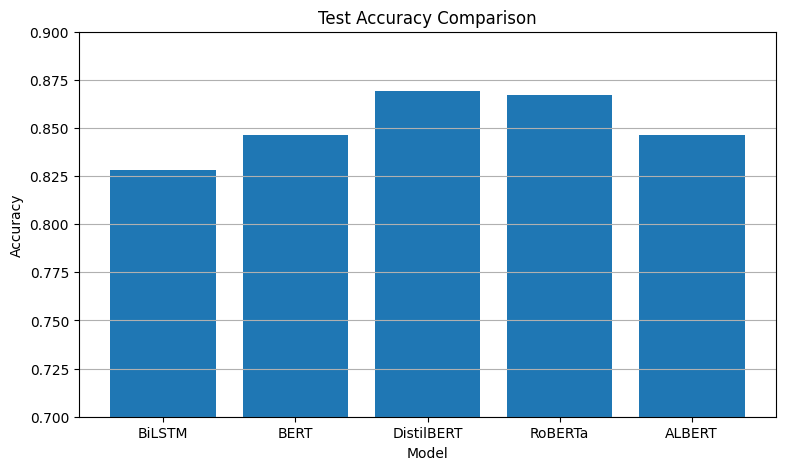

In [ ]:
# Accuracy Comparison

plt.figure(figsize=(9, 5))

plt.bar(models, test_accuracy)

plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.title("Test Accuracy Comparison")

plt.ylim(0.7, 0.9)
plt.grid(axis="y")

plt.show()

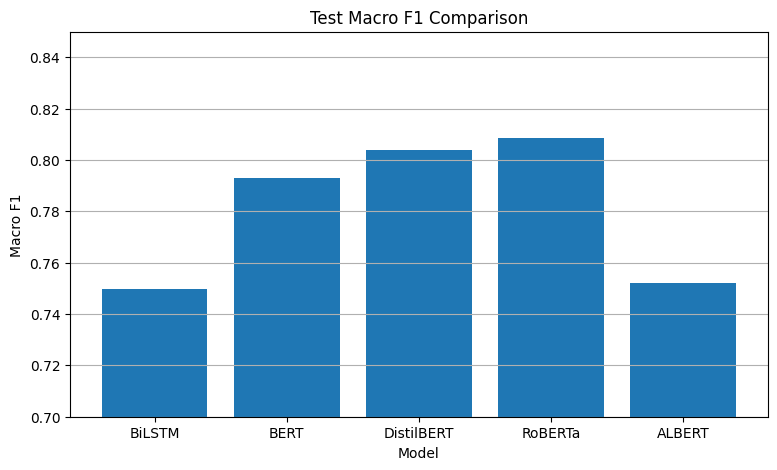

In [ ]:
# Marco F1 comparison

plt.figure(figsize=(9, 5))

plt.bar(models, macro_f1)

plt.xlabel("Model")
plt.ylabel("Macro F1")
plt.title("Test Macro F1 Comparison")

plt.ylim(0.7, 0.85)
plt.grid(axis="y")

plt.show()

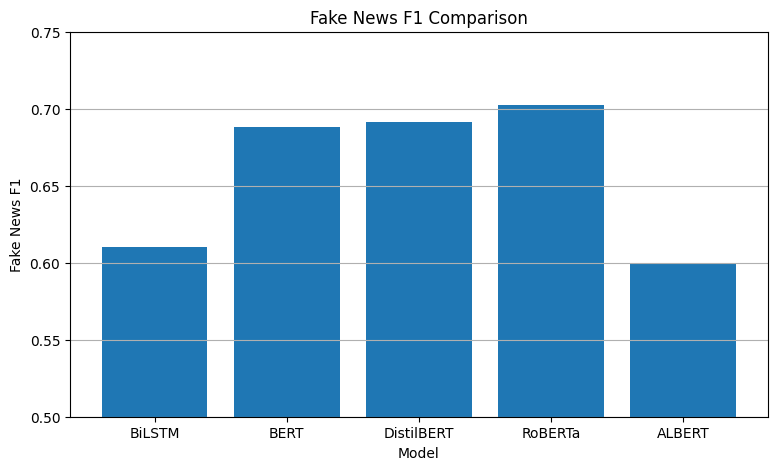

In [ ]:
# Fake news f1 comparison

plt.figure(figsize=(9, 5))

plt.bar(models, fake_f1)

plt.xlabel("Model")
plt.ylabel("Fake News F1")
plt.title("Fake News F1 Comparison")

plt.ylim(0.5, 0.75)
plt.grid(axis="y")

plt.show()

In [ ]:
baseline_results = {
    "BiLSTM": {
        "accuracy": 0.8280,
        "macro_f1": 0.7498,
        "fake_f1": 0.6100
    },
    "BERT": {
        "accuracy": 0.8461,
        "macro_f1": 0.7930,
        "fake_f1": 0.6882
    },
    "DistilBERT": {
        "accuracy": 0.8690,
        "macro_f1": 0.8040,
        "fake_f1": 0.6911
    },
    "RoBERTa": {
        "accuracy": 0.8672,
        "macro_f1": 0.8086,
        "fake_f1": 0.7027
    },
    "ALBERT": {
        "accuracy": 0.8461,
        "macro_f1": 0.7521,
        "fake_f1": 0.5993
    }
}

baseline_results

{'BiLSTM': {'accuracy': 0.828, 'macro_f1': 0.7498, 'fake_f1': 0.61},
 'BERT': {'accuracy': 0.8461, 'macro_f1': 0.793, 'fake_f1': 0.6882},
 'DistilBERT': {'accuracy': 0.869, 'macro_f1': 0.804, 'fake_f1': 0.6911},
 'RoBERTa': {'accuracy': 0.8672, 'macro_f1': 0.8086, 'fake_f1': 0.7027},
 'ALBERT': {'accuracy': 0.8461, 'macro_f1': 0.7521, 'fake_f1': 0.5993}}

## DAY 2

In [ ]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
from collections import Counter
import re

In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [ ]:
print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))

print("\nTrain labels:")
print(y_train.value_counts())

print("\nValidation labels:")
print(y_val.value_counts())

print("\nTest labels:")
print(y_test.value_counts())

Train: 18556
Validation: 2320
Test: 2320

Train labels:
real
1    13952
0     4604
Name: count, dtype: int64

Validation labels:
real
1    1745
0     575
Name: count, dtype: int64

Test labels:
real
1    1744
0     576
Name: count, dtype: int64


In [ ]:
import os

print(os.path.exists("best_bilstm_model.pth"))

False


In [ ]:
weighted_bilstm = BiLSTMClassifier(
    vocab_size=len(vocab),
    embedding_dim=128,
    hidden_dim=128,
    num_layers=2,
    dropout=0.3
).to(device)

In [ ]:
# Loading yesterday model

weighted_bilstm.load_state_dict(
    torch.load("/content/best_bilstm_model.pth", map_location=device)
)

weighted_bilstm.eval()

print("Baseline BiLSTM checkpoint loaded successfully! ✅")

Baseline BiLSTM checkpoint loaded successfully! ✅


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def evaluate(model, loader, criterion):
    model.eval()

    total_loss = 0
    all_predictions = []
    all_labels = []

    with torch.no_grad():
        for texts, labels in loader:
            texts = texts.to(device)
            labels = labels.to(device)

            outputs = model(texts)

            loss = criterion(outputs, labels)
            total_loss += loss.item()

            probabilities = torch.sigmoid(outputs)
            predictions = (probabilities >= 0.5).long()

            all_predictions.extend(
                predictions.cpu().numpy()
            )
            all_labels.extend(
                labels.cpu().numpy()
            )

    avg_loss = total_loss / len(loader)

    accuracy = accuracy_score(all_labels, all_predictions)
    precision = precision_score(all_labels, all_predictions)
    recall = recall_score(all_labels, all_predictions)
    f1 = f1_score(all_labels, all_predictions)

    return (
        avg_loss,
        accuracy,
        precision,
        recall,
        f1,
        all_labels,
        all_predictions
    )

In [ ]:
criterion = nn.BCEWithLogitsLoss()

In [ ]:
test_loss, test_acc, test_precision, test_recall, test_f1, test_labels, test_predictions = evaluate(
    weighted_bilstm,
    test_loader,
    criterion
)

test_macro_f1 = f1_score(
    test_labels,
    test_predictions,
    average="macro"
)

print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test F1: {test_f1:.4f}")
print(f"Test Macro F1: {test_macro_f1:.4f}")

Test Accuracy: 0.8280
Test F1: 0.8897
Test Macro F1: 0.7498


In [ ]:
# Calculating the weights

from collections import Counter

class_counts = Counter(y_train)

fake_count = class_counts[0]
real_count = class_counts[1]

fake_weight = real_count / fake_count
real_weight = 1.0

print("Fake count:", fake_count)
print("Real count:", real_count)
print("Fake weight:", fake_weight)
print("Real weight:", real_weight)

Fake count: 4604
Real count: 13952
Fake weight: 3.0304083405734143
Real weight: 1.0


In [ ]:
# Creating the weighted loss

criterion_weighted = nn.BCEWithLogitsLoss(reduction="none")

In [ ]:
# Creating the weighted training function

def train_one_epoch_weighted(model, loader, criterion):
    model.train()

    total_loss = 0
    all_predictions = []
    all_labels = []

    for texts, labels in loader:
        texts = texts.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(texts)

        # Calculate loss for each sample
        losses = criterion(outputs, labels)

        # Give Fake (0) higher importance
        sample_weights = torch.where(
            labels == 0,
            torch.tensor(fake_weight, device=device),
            torch.tensor(real_weight, device=device)
        )

        weighted_loss = (losses * sample_weights).mean()

        weighted_loss.backward()
        optimizer.step()

        total_loss += weighted_loss.item()

        probabilities = torch.sigmoid(outputs)
        predictions = (probabilities >= 0.5).long()

        all_predictions.extend(
            predictions.detach().cpu().numpy()
        )
        all_labels.extend(
            labels.detach().cpu().numpy()
        )

    avg_loss = total_loss / len(loader)

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    f1 = f1_score(
        all_labels,
        all_predictions
    )

    return avg_loss, accuracy, f1

In [ ]:
# Creating fresh model

weighted_bilstm = BiLSTMClassifier(
    vocab_size=len(vocab),
    embedding_dim=128,
    hidden_dim=128,
    num_layers=2,
    dropout=0.3
).to(device)

In [ ]:
# Setting the optimizer

optimizer = torch.optim.Adam(
    weighted_bilstm.parameters(),
    lr=0.001
)

In [ ]:
# Training for 5 epoch

EPOCHS = 5

best_weighted_val_macro_f1 = 0.0

weighted_history = {
    "train_loss": [],
    "train_f1": [],
    "val_loss": [],
    "val_f1": [],
    "val_macro_f1": []
}

for epoch in range(EPOCHS):

    train_loss, train_acc, train_f1 = train_one_epoch_weighted(
        weighted_bilstm,
        train_loader,
        criterion_weighted
    )

    (
        val_loss,
        val_acc,
        val_precision,
        val_recall,
        val_f1,
        val_labels,
        val_predictions
    ) = evaluate(
        weighted_bilstm,
        val_loader,
        criterion
    )

    val_macro_f1 = f1_score(
        val_labels,
        val_predictions,
        average="macro"
    )

    weighted_history["train_loss"].append(train_loss)
    weighted_history["train_f1"].append(train_f1)
    weighted_history["val_loss"].append(val_loss)
    weighted_history["val_f1"].append(val_f1)
    weighted_history["val_macro_f1"].append(val_macro_f1)

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train F1: {train_f1:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val F1: {val_f1:.4f} | "
        f"Val Macro F1: {val_macro_f1:.4f}"
    )

    if val_macro_f1 > best_weighted_val_macro_f1:
        best_weighted_val_macro_f1 = val_macro_f1

        torch.save(
            weighted_bilstm.state_dict(),
            "best_bilstm_weighted.pth"
        )

        print("  ✅ Best model saved!")

Epoch 1/5 | Train Loss: 0.8629 | Train F1: 0.8005 | Val Loss: 0.5087 | Val F1: 0.8210 | Val Macro F1: 0.7114
  ✅ Best model saved!
Epoch 2/5 | Train Loss: 0.6668 | Train F1: 0.8547 | Val Loss: 0.4297 | Val F1: 0.8709 | Val Macro F1: 0.7597
  ✅ Best model saved!
Epoch 3/5 | Train Loss: 0.5146 | Train F1: 0.8891 | Val Loss: 0.4649 | Val F1: 0.8514 | Val Macro F1: 0.7458
Epoch 4/5 | Train Loss: 0.3795 | Train F1: 0.9241 | Val Loss: 0.5392 | Val F1: 0.8316 | Val Macro F1: 0.7320
Epoch 5/5 | Train Loss: 0.2606 | Train F1: 0.9485 | Val Loss: 0.5757 | Val F1: 0.8695 | Val Macro F1: 0.7508


lower learning rate optimization

In [ ]:
# Fresh LSTM

bilstm_lr = BiLSTMClassifier(
    vocab_size=len(vocab),
    embedding_dim=128,
    hidden_dim=128,
    num_layers=2,
    dropout=0.3
).to(device)

In [ ]:
# optimizer

optimizer = torch.optim.Adam(
    bilstm_lr.parameters(),
    lr=0.0005
)

In [ ]:
# Train

criterion = nn.BCEWithLogitsLoss()

In [ ]:
def train_one_epoch(model, loader, criterion):
    model.train()

    total_loss = 0
    all_predictions = []
    all_labels = []

    for texts, labels in loader:
        texts = texts.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(texts)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        probabilities = torch.sigmoid(outputs)
        predictions = (probabilities >= 0.5).long()

        all_predictions.extend(
            predictions.detach().cpu().numpy()
        )
        all_labels.extend(
            labels.detach().cpu().numpy()
        )

    avg_loss = total_loss / len(loader)

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    f1 = f1_score(
        all_labels,
        all_predictions
    )

    return avg_loss, accuracy, f1

In [ ]:
EPOCHS = 5

best_lr_val_macro_f1 = 0.0

lr_history = {
    "train_loss": [],
    "train_f1": [],
    "val_loss": [],
    "val_f1": [],
    "val_macro_f1": []
}

for epoch in range(EPOCHS):

    train_loss, train_acc, train_f1 = train_one_epoch(
        bilstm_lr,
        train_loader,
        criterion
    )

    (
        val_loss,
        val_acc,
        val_precision,
        val_recall,
        val_f1,
        val_labels,
        val_predictions
    ) = evaluate(
        bilstm_lr,
        val_loader,
        criterion
    )

    val_macro_f1 = f1_score(
        val_labels,
        val_predictions,
        average="macro"
    )

    lr_history["train_loss"].append(train_loss)
    lr_history["train_f1"].append(train_f1)
    lr_history["val_loss"].append(val_loss)
    lr_history["val_f1"].append(val_f1)
    lr_history["val_macro_f1"].append(val_macro_f1)

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train F1: {train_f1:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val F1: {val_f1:.4f} | "
        f"Val Macro F1: {val_macro_f1:.4f}"
    )

    if val_macro_f1 > best_lr_val_macro_f1:
        best_lr_val_macro_f1 = val_macro_f1

        torch.save(
            bilstm_lr.state_dict(),
            "best_bilstm_lr.pth"
        )

        print("  ✅ Best model saved!")

Epoch 1/5 | Train Loss: 0.4891 | Train F1: 0.8709 | Val Loss: 0.4350 | Val F1: 0.8862 | Val Macro F1: 0.7029
  ✅ Best model saved!
Epoch 2/5 | Train Loss: 0.3888 | Train F1: 0.8955 | Val Loss: 0.4121 | Val F1: 0.8891 | Val Macro F1: 0.7421
  ✅ Best model saved!
Epoch 3/5 | Train Loss: 0.3289 | Train F1: 0.9099 | Val Loss: 0.4094 | Val F1: 0.8901 | Val Macro F1: 0.7564
  ✅ Best model saved!
Epoch 4/5 | Train Loss: 0.2662 | Train F1: 0.9285 | Val Loss: 0.4193 | Val F1: 0.8945 | Val Macro F1: 0.7578
  ✅ Best model saved!
Epoch 5/5 | Train Loss: 0.2090 | Train F1: 0.9455 | Val Loss: 0.4803 | Val F1: 0.8777 | Val Macro F1: 0.7495


In [ ]:
baseline_bilstm = BiLSTMClassifier(
    vocab_size=len(vocab),
    embedding_dim=128,
    hidden_dim=128,
    num_layers=2,
    dropout=0.3
).to(device)

baseline_bilstm.load_state_dict(
    torch.load("/content/best_bilstm_model.pth", map_location=device)
)

baseline_bilstm.eval()

BiLSTMClassifier(
  (embedding): Embedding(12118, 128, padding_idx=0)
  (lstm): LSTM(128, 128, num_layers=2, batch_first=True, dropout=0.3, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=256, out_features=1, bias=True)
)

In [ ]:
(
    val_loss,
    val_acc,
    val_precision,
    val_recall,
    val_f1,
    val_labels,
    val_predictions
) = evaluate(
    baseline_bilstm,
    val_loader,
    criterion
)

baseline_val_macro_f1 = f1_score(
    val_labels,
    val_predictions,
    average="macro"
)

print(f"Validation Accuracy: {val_acc:.4f}")
print(f"Validation F1: {val_f1:.4f}")
print(f"Validation Macro F1: {baseline_val_macro_f1:.4f}")

Validation Accuracy: 0.8444
Validation F1: 0.9010
Validation Macro F1: 0.7691


In [ ]:
bilstm_optimization_results = {
    "Baseline": {
        "val_macro_f1": 0.7691,
        "test_macro_f1": 0.7498,
        "test_accuracy": 0.8280,
        "fake_f1": 0.6100
    },
    "Class Weighted Loss": {
        "best_val_macro_f1": 0.7597,
        "decision": "Rejected"
    },
    "Learning Rate 0.0005": {
        "best_val_macro_f1": 0.7578,
        "decision": "Rejected"
    }
}

now dropout optimization

In [ ]:
# BiLSTM with higher dropout
bilstm_dropout = BiLSTMClassifier(
    vocab_size=len(vocab),
    embedding_dim=128,
    hidden_dim=128,
    num_layers=2,
    dropout=0.5
).to(device)

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    bilstm_dropout.parameters(),
    lr=0.001
)

print("BiLSTM with Dropout = 0.5 created!")


BiLSTM with Dropout = 0.5 created!


In [ ]:
# training

best_val_macro_f1 = 0.0
best_epoch = 0

train_losses = []
val_losses = []
train_f1s = []
val_f1s = []
val_macro_f1s = []

for epoch in range(5):

    train_loss, train_acc, train_f1 = train_one_epoch(
        bilstm_dropout,
        train_loader,
        criterion
    )

    val_loss, val_acc, val_precision, val_recall, val_f1, val_labels, val_predictions = evaluate(
        bilstm_dropout,
        val_loader,
        criterion
    )

    val_macro_f1 = f1_score(
        val_labels,
        val_predictions,
        average="macro"
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_f1s.append(train_f1)
    val_f1s.append(val_f1)
    val_macro_f1s.append(val_macro_f1)

    print(
        f"Epoch {epoch+1}/5 | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train F1: {train_f1:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val F1: {val_f1:.4f} | "
        f"Val Macro F1: {val_macro_f1:.4f}"
    )

    # Save based on Macro F1
    if val_macro_f1 > best_val_macro_f1:
        best_val_macro_f1 = val_macro_f1
        best_epoch = epoch + 1

        torch.save(
            bilstm_dropout.state_dict(),
            "/content/best_bilstm_dropout.pth"
        )

print("\nBest Epoch:", best_epoch)
print("Best Validation Macro F1:", round(best_val_macro_f1, 4))

Epoch 1/5 | Train Loss: 0.4729 | Train F1: 0.8740 | Val Loss: 0.4458 | Val F1: 0.8734 | Val Macro F1: 0.7331
Epoch 2/5 | Train Loss: 0.3729 | Train F1: 0.8999 | Val Loss: 0.3967 | Val F1: 0.8958 | Val Macro F1: 0.7541
Epoch 3/5 | Train Loss: 0.3031 | Train F1: 0.9180 | Val Loss: 0.4209 | Val F1: 0.8930 | Val Macro F1: 0.7507
Epoch 4/5 | Train Loss: 0.2362 | Train F1: 0.9364 | Val Loss: 0.4674 | Val F1: 0.8844 | Val Macro F1: 0.7448
Epoch 5/5 | Train Loss: 0.1760 | Train F1: 0.9534 | Val Loss: 0.5362 | Val F1: 0.8906 | Val Macro F1: 0.7512

Best Epoch: 2
Best Validation Macro F1: 0.7541


optimization by changing the hidden dimension of lstm


In [ ]:
bilstm_hidden64 = BiLSTMClassifier(
    vocab_size=len(vocab),
    embedding_dim=128,
    hidden_dim=64,
    num_layers=2,
    dropout=0.3
).to(device)

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    bilstm_hidden64.parameters(),
    lr=0.001
)

print("BiLSTM with Hidden Size = 64 created!")

BiLSTM with Hidden Size = 64 created!


In [ ]:
# training

best_val_macro_f1 = 0.0
best_epoch = 0

for epoch in range(5):

    train_loss, train_acc, train_f1 = train_one_epoch(
        bilstm_hidden64,
        train_loader,
        criterion
    )

    val_loss, val_acc, val_precision, val_recall, val_f1, val_labels, val_predictions = evaluate(
        bilstm_hidden64,
        val_loader,
        criterion
    )

    val_macro_f1 = f1_score(
        val_labels,
        val_predictions,
        average="macro"
    )

    print(
        f"Epoch {epoch+1}/5 | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train F1: {train_f1:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val F1: {val_f1:.4f} | "
        f"Val Macro F1: {val_macro_f1:.4f}"
    )

    if val_macro_f1 > best_val_macro_f1:
        best_val_macro_f1 = val_macro_f1
        best_epoch = epoch + 1

        torch.save(
            bilstm_hidden64.state_dict(),
            "/content/best_bilstm_hidden64.pth"
        )

print("\nBest Epoch:", best_epoch)
print("Best Validation Macro F1:", round(best_val_macro_f1, 4))

Epoch 1/5 | Train Loss: 0.4800 | Train F1: 0.8732 | Val Loss: 0.4147 | Val F1: 0.8872 | Val Macro F1: 0.7375
Epoch 2/5 | Train Loss: 0.3669 | Train F1: 0.9002 | Val Loss: 0.3967 | Val F1: 0.8938 | Val Macro F1: 0.7636
Epoch 3/5 | Train Loss: 0.2904 | Train F1: 0.9211 | Val Loss: 0.3942 | Val F1: 0.9017 | Val Macro F1: 0.7826
Epoch 4/5 | Train Loss: 0.2211 | Train F1: 0.9414 | Val Loss: 0.4393 | Val F1: 0.8846 | Val Macro F1: 0.7648
Epoch 5/5 | Train Loss: 0.1580 | Train F1: 0.9605 | Val Loss: 0.5633 | Val F1: 0.8795 | Val Macro F1: 0.7562

Best Epoch: 3
Best Validation Macro F1: 0.7826


Bidirectional architecture tuning

In [ ]:
bilstm_1layer = BiLSTMClassifier(
    vocab_size=len(vocab),
    embedding_dim=128,
    hidden_dim=64,
    num_layers=1,
    dropout=0.3
).to(device)

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    bilstm_1layer.parameters(),
    lr=0.001
)

print("BiLSTM with 1 LSTM layer created!")

BiLSTM with 1 LSTM layer created!


In [ ]:
# training

best_val_macro_f1 = 0.0
best_epoch = 0

for epoch in range(5):

    train_loss, train_acc, train_f1 = train_one_epoch(
        bilstm_1layer,
        train_loader,
        criterion
    )

    val_loss, val_acc, val_precision, val_recall, val_f1, val_labels, val_predictions = evaluate(
        bilstm_1layer,
        val_loader,
        criterion
    )

    val_macro_f1 = f1_score(
        val_labels,
        val_predictions,
        average="macro"
    )

    print(
        f"Epoch {epoch+1}/5 | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train F1: {train_f1:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val F1: {val_f1:.4f} | "
        f"Val Macro F1: {val_macro_f1:.4f}"
    )

    if val_macro_f1 > best_val_macro_f1:
        best_val_macro_f1 = val_macro_f1
        best_epoch = epoch + 1

        torch.save(
            bilstm_1layer.state_dict(),
            "/content/best_bilstm_1layer.pth"
        )

print("\nBest Epoch:", best_epoch)
print("Best Validation Macro F1:", round(best_val_macro_f1, 4))

Epoch 1/5 | Train Loss: 0.4941 | Train F1: 0.8710 | Val Loss: 0.4298 | Val F1: 0.8849 | Val Macro F1: 0.7099
Epoch 2/5 | Train Loss: 0.3790 | Train F1: 0.8975 | Val Loss: 0.4073 | Val F1: 0.8944 | Val Macro F1: 0.7645
Epoch 3/5 | Train Loss: 0.3083 | Train F1: 0.9184 | Val Loss: 0.3965 | Val F1: 0.8965 | Val Macro F1: 0.7681
Epoch 4/5 | Train Loss: 0.2470 | Train F1: 0.9341 | Val Loss: 0.4279 | Val F1: 0.8940 | Val Macro F1: 0.7626
Epoch 5/5 | Train Loss: 0.1872 | Train F1: 0.9523 | Val Loss: 0.4666 | Val F1: 0.8875 | Val Macro F1: 0.7612

Best Epoch: 3
Best Validation Macro F1: 0.7681


sequence length tuning (50 → 75) optimization



In [ ]:
# creating dataset

# Save original sequence length
ORIGINAL_MAX_LENGTH = MAX_LENGTH

# Change sequence length
MAX_LENGTH = 75

train_dataset_75 = FakeNewsDataset(
    X_train,
    y_train
)

val_dataset_75 = FakeNewsDataset(
    X_val,
    y_val
)

test_dataset_75 = FakeNewsDataset(
    X_test,
    y_test
)

train_loader_75 = DataLoader(
    train_dataset_75,
    batch_size=64,
    shuffle=True
)

val_loader_75 = DataLoader(
    val_dataset_75,
    batch_size=64,
    shuffle=False
)

test_loader_75 = DataLoader(
    test_dataset_75,
    batch_size=64,
    shuffle=False
)

# Restore original value
MAX_LENGTH = ORIGINAL_MAX_LENGTH

print("DataLoaders with MAX_LENGTH = 75 created successfully!")

DataLoaders with MAX_LENGTH = 75 created successfully!


In [ ]:
# Creating BiLSTM model

bilstm_len75 = BiLSTMClassifier(
    vocab_size=len(vocab),
    embedding_dim=128,
    hidden_dim=64,
    num_layers=2,
    dropout=0.3
).to(device)

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    bilstm_len75.parameters(),
    lr=0.001
)

print("BiLSTM with sequence length 75 created!")

BiLSTM with sequence length 75 created!


In [ ]:
# training

best_val_macro_f1 = 0.0
best_epoch = 0

for epoch in range(5):

    train_loss, train_acc, train_f1 = train_one_epoch(
        bilstm_len75,
        train_loader_75,
        criterion
    )

    val_loss, val_acc, val_precision, val_recall, val_f1, val_labels, val_predictions = evaluate(
        bilstm_len75,
        val_loader_75,
        criterion
    )

    val_macro_f1 = f1_score(
        val_labels,
        val_predictions,
        average="macro"
    )

    print(
        f"Epoch {epoch+1}/5 | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train F1: {train_f1:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val F1: {val_f1:.4f} | "
        f"Val Macro F1: {val_macro_f1:.4f}"
    )

    if val_macro_f1 > best_val_macro_f1:
        best_val_macro_f1 = val_macro_f1
        best_epoch = epoch + 1

        torch.save(
            bilstm_len75.state_dict(),
            "/content/best_bilstm_len75.pth"
        )

print("\nBest Epoch:", best_epoch)
print("Best Validation Macro F1:", round(best_val_macro_f1, 4))

Epoch 1/5 | Train Loss: 0.4750 | Train F1: 0.8759 | Val Loss: 0.4160 | Val F1: 0.8948 | Val Macro F1: 0.7650
Epoch 2/5 | Train Loss: 0.3614 | Train F1: 0.9047 | Val Loss: 0.4025 | Val F1: 0.8991 | Val Macro F1: 0.7546
Epoch 3/5 | Train Loss: 0.2917 | Train F1: 0.9233 | Val Loss: 0.4068 | Val F1: 0.8892 | Val Macro F1: 0.7776
Epoch 4/5 | Train Loss: 0.2207 | Train F1: 0.9439 | Val Loss: 0.4373 | Val F1: 0.8943 | Val Macro F1: 0.7734
Epoch 5/5 | Train Loss: 0.1658 | Train F1: 0.9592 | Val Loss: 0.4852 | Val F1: 0.8935 | Val Macro F1: 0.7734

Best Epoch: 3
Best Validation Macro F1: 0.7776


In all 6 optimization our best was reducing size

Reducing hidden size from 128 → 64 improved generalization, while increasing sequence length or reducing layers didn't help.

In [ ]:
# Loading the optimized model

optimized_bilstm = BiLSTMClassifier(
    vocab_size=len(vocab),
    embedding_dim=128,
    hidden_dim=64,
    num_layers=2,
    dropout=0.3
).to(device)

optimized_bilstm.load_state_dict(
    torch.load(
        "/content/best_bilstm_hidden64.pth",
        map_location=device
    )
)

print("Optimized BiLSTM checkpoint loaded!")

Optimized BiLSTM checkpoint loaded!


In [ ]:
# Evaluating our best model on our test data

test_loss, test_acc, test_precision, test_recall, test_f1, test_labels, test_predictions = evaluate(
    optimized_bilstm,
    test_loader,
    criterion
)

test_macro_f1 = f1_score(
    test_labels,
    test_predictions,
    average="macro"
)

print("Optimized BiLSTM Test Results")
print("--------------------------------")
print(f"Accuracy       : {test_acc:.4f}")
print(f"Precision      : {test_precision:.4f}")
print(f"Recall         : {test_recall:.4f}")
print(f"F1 (Real)      : {test_f1:.4f}")
print(f"Macro F1       : {test_macro_f1:.4f}")

Optimized BiLSTM Test Results
--------------------------------
Accuracy       : 0.8366
Precision      : 0.8740
Recall         : 0.9146
F1 (Real)      : 0.8938
Macro F1       : 0.7700


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

In [ ]:
print("\nClassification Report:")
print(
    classification_report(
        test_labels,
        test_predictions,
        target_names=["Fake", "Real"],
        digits=4
    )
)


Classification Report:
              precision    recall  f1-score   support

        Fake     0.6990    0.6007    0.6461       576
        Real     0.8740    0.9146    0.8938      1744

    accuracy                         0.8366      2320
   macro avg     0.7865    0.7576    0.7700      2320
weighted avg     0.8305    0.8366    0.8323      2320



In [ ]:
cm = confusion_matrix(
    test_labels,
    test_predictions
)

print("\nConfusion Matrix:")
print(cm)


Confusion Matrix:
[[ 346  230]
 [ 149 1595]]


### Optimizing model 2 BERT

In [ ]:
from transformers import BertForSequenceClassification
from torch.utils.data import Dataset, DataLoader
from transformers import BertTokenizer
import torch

bert_tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")

print("Tokenizer loaded!")

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tokenizer loaded!


In [ ]:
# Loading/creating BERT

bert_lr = BertForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=2
).to(device)

optimizer = torch.optim.AdamW(
    bert_lr.parameters(),
    lr=3e-5
)

print("BERT with learning rate = 3e-5 created!")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT with learning rate = 3e-5 created!


In [ ]:
# BERT tokenizer
from transformers import BertTokenizer

bert_tokenizer = BertTokenizer.from_pretrained(
    "bert-base-uncased"
)

print("BERT tokenizer loaded!")

BERT tokenizer loaded!


In [ ]:
# dataset

class BertDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length=64):
        self.texts = list(texts)
        self.labels = list(labels)
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoding = self.tokenizer(
            str(self.texts[idx]),
            padding="max_length",
            truncation=True,
            max_length=self.max_length,
            return_tensors="pt"
        )

        return {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "labels": torch.tensor(
                self.labels[idx],
                dtype=torch.long
            )
        }

print("BertDataset recreated!")

BertDataset recreated!


In [ ]:
# loaders

train_dataset_bert = BertDataset(
    X_train,
    y_train,
    bert_tokenizer,
    max_length=64
)

val_dataset_bert = BertDataset(
    X_val,
    y_val,
    bert_tokenizer,
    max_length=64
)

test_dataset_bert = BertDataset(
    X_test,
    y_test,
    bert_tokenizer,
    max_length=64
)

train_loader_bert = DataLoader(
    train_dataset_bert,
    batch_size=16,
    shuffle=True
)

val_loader_bert = DataLoader(
    val_dataset_bert,
    batch_size=16,
    shuffle=False
)

test_loader_bert = DataLoader(
    test_dataset_bert,
    batch_size=16,
    shuffle=False
)

print("BERT DataLoaders recreated successfully!")

BERT DataLoaders recreated successfully!


In [ ]:
from torch.utils.data import Dataset, DataLoader
from transformers import BertTokenizer
import torch

bert_tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")

print("Tokenizer loaded!")

Tokenizer loaded!


In [ ]:
batch = next(iter(train_loader_bert))

print("Input IDs shape:", batch["input_ids"].shape)
print("Attention mask shape:", batch["attention_mask"].shape)
print("Labels shape:", batch["labels"].shape)

Input IDs shape: torch.Size([16, 64])
Attention mask shape: torch.Size([16, 64])
Labels shape: torch.Size([16])


In [ ]:
import os

path = "/content/best_bert_model.pth"

print("Exists:", os.path.exists(path))

if os.path.exists(path):
    print("Size:", os.path.getsize(path) / (1024 * 1024), "MB")

Exists: True
Size: 418.4545383453369 MB


In [ ]:
with open("/content/best_bert_model.pth", "rb") as f:
    print(f.read(20))


b'm\x1a\x17=4\xfb\xc8<\x84\xb2\x80=g\xd2V\xbd\\Y1\xbd'


In [ ]:
import os

path = "/content/best_bert_model.pth"

with open(path, "rb") as f:
    data = f.read(100)

print("First 100 bytes:")
print(data)

print("\nFile size:")
print(os.path.getsize(path) / (1024 * 1024), "MB")

First 100 bytes:
b'm\x1a\x17=4\xfb\xc8<\x84\xb2\x80=g\xd2V\xbd\\Y1\xbdPD\xf7<\xd9\xfa\xc5\xbc\x7f\xc9\xeb\xbc ?\xb4\xbb\x9d\xc14\xbdSZ\x91\xbd\xe1x<\xbd\x18(\x939\x03FS=\xca/H=T\xba\x92;,\x84\xca\xbb\x17P\r\xbb\xf8\x04\xc2\xbc\x9ct\x10\xbclu*\xbd\xc1\x84\x15\xbc\xb6\x9f\x99;\xa5\xb4\t=\xfba}\xbb'

File size:
418.4545383453369 MB


In [ ]:
!file /content/best_bert_model.pth

/content/best_bert_model.pth: data


In [ ]:
print("Device:", device)
print("Train batches:", len(train_loader_bert))
print("Validation batches:", len(val_loader_bert))

Device: cuda
Train batches: 1160
Validation batches: 145


In [ ]:
# fresh BERT model

from transformers import BertForSequenceClassification

bert_baseline = BertForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=2
).to(device)

print("BERT model ready!")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT model ready!


In [ ]:
# optimizer

from torch.optim import AdamW

bert_optimizer = AdamW(
    bert_baseline.parameters(),
    lr=2e-5
)

In [ ]:
# training

from sklearn.metrics import f1_score, accuracy_score
import torch

EPOCHS = 3

best_macro_f1 = 0.0
best_epoch = 0

train_losses = []
val_losses = []
train_f1s = []
val_f1s = []
val_macro_f1s = []

for epoch in range(EPOCHS):

    # =========================
    # TRAIN
    # =========================
    bert_baseline.train()

    total_train_loss = 0
    train_preds = []
    train_labels = []

    for batch in train_loader_bert:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        bert_optimizer.zero_grad()

        outputs = bert_baseline(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss
        logits = outputs.logits

        loss.backward()
        bert_optimizer.step()

        total_train_loss += loss.item()

        preds = torch.argmax(logits, dim=1)

        train_preds.extend(preds.detach().cpu().numpy())
        train_labels.extend(labels.detach().cpu().numpy())

    avg_train_loss = total_train_loss / len(train_loader_bert)

    train_accuracy = accuracy_score(
        train_labels,
        train_preds
    )

    train_f1 = f1_score(
        train_labels,
        train_preds
    )

    # =========================
    # VALIDATION
    # =========================
    bert_baseline.eval()

    total_val_loss = 0
    val_preds = []
    val_labels = []

    with torch.no_grad():

        for batch in val_loader_bert:

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            outputs = bert_baseline(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            loss = outputs.loss
            logits = outputs.logits

            total_val_loss += loss.item()

            preds = torch.argmax(logits, dim=1)

            val_preds.extend(preds.cpu().numpy())
            val_labels.extend(labels.cpu().numpy())

    avg_val_loss = total_val_loss / len(val_loader_bert)

    val_accuracy = accuracy_score(
        val_labels,
        val_preds
    )

    # Real-class F1 — kept for comparison with our old experiments
    val_f1 = f1_score(
        val_labels,
        val_preds
    )

    # IMPORTANT: our actual selection metric
    val_macro_f1 = f1_score(
        val_labels,
        val_preds,
        average="macro"
    )

    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)
    train_f1s.append(train_f1)
    val_f1s.append(val_f1)
    val_macro_f1s.append(val_macro_f1)

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Train F1: {train_f1:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Val F1: {val_f1:.4f} | "
        f"Val Macro F1: {val_macro_f1:.4f}"
    )

    # =========================
    # SAVE BEST MODEL
    # =========================
    if val_macro_f1 > best_macro_f1:

        best_macro_f1 = val_macro_f1
        best_epoch = epoch + 1

        torch.save(
            bert_baseline.state_dict(),
            "/content/best_bert_model.pth"
        )

        print(
            f"  --> New best model saved! "
            f"Macro F1 = {best_macro_f1:.4f}"
        )

print("\nTraining complete!")
print("Best Epoch:", best_epoch)
print("Best Validation Macro F1:", f"{best_macro_f1:.4f}")

Epoch 1/3 | Train Loss: 0.3993 | Train F1: 0.8936 | Val Loss: 0.3413 | Val F1: 0.9149 | Val Macro F1: 0.8088
  --> New best model saved! Macro F1 = 0.8088
Epoch 2/3 | Train Loss: 0.2721 | Train F1: 0.9295 | Val Loss: 0.3349 | Val F1: 0.9147 | Val Macro F1: 0.7985
Epoch 3/3 | Train Loss: 0.1809 | Train F1: 0.9543 | Val Loss: 0.3852 | Val F1: 0.9160 | Val Macro F1: 0.8256
  --> New best model saved! Macro F1 = 0.8256

Training complete!
Best Epoch: 3
Best Validation Macro F1: 0.8256


In [ ]:
import os

path = "/content/best_bert_model.pth"

print("Exists:", os.path.exists(path))
print("Size:", os.path.getsize(path) / (1024 * 1024), "MB")

test_checkpoint = torch.load(
    path,
    map_location="cpu",
    weights_only=True
)

print("Checkpoint verification: SUCCESS!")
print("Number of tensors:", len(test_checkpoint))

Exists: True
Size: 417.72726917266846 MB
Checkpoint verification: SUCCESS!
Number of tensors: 201


In [ ]:
import os
import torch

path = "/content/best_bert_model.pth"

print("File exists:", os.path.exists(path))

if os.path.exists(path):

    print("File size:",
          round(os.path.getsize(path) / (1024 * 1024), 2),
          "MB")

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    print("Checkpoint verification: SUCCESS!")
    print("Number of tensors:", len(checkpoint))

else:
    print("ERROR: Checkpoint file not found!")

File exists: True
File size: 417.73 MB
Checkpoint verification: SUCCESS!
Number of tensors: 201


In [ ]:
# evaluation

from transformers import BertForSequenceClassification
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import torch

# Load the verified best checkpoint
bert_baseline = BertForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=2
).to(device)

checkpoint = torch.load(
    "/content/best_bert_model.pth",
    map_location=device,
    weights_only=True
)

bert_baseline.load_state_dict(checkpoint)
bert_baseline.eval()

# Test evaluation
all_preds = []
all_labels = []

with torch.no_grad():

    for batch in test_loader_bert:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = bert_baseline(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        preds = torch.argmax(outputs.logits, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())


# Metrics
accuracy = accuracy_score(all_labels, all_preds)

fake_f1 = f1_score(
    all_labels,
    all_preds,
    pos_label=0
)

real_f1 = f1_score(
    all_labels,
    all_preds,
    pos_label=1
)

macro_f1 = f1_score(
    all_labels,
    all_preds,
    average="macro"
)

precision = precision_score(all_labels, all_preds)
recall = recall_score(all_labels, all_preds)

print("=" * 50)
print("BERT BASELINE — TEST RESULTS")
print("=" * 50)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"Fake F1   : {fake_f1:.4f}")
print(f"Real F1   : {real_f1:.4f}")
print(f"Macro F1  : {macro_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_preds,
    target_names=["Fake", "Real"],
    digits=4
))

print("\nConfusion Matrix:")
print(confusion_matrix(all_labels, all_preds))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT BASELINE — TEST RESULTS
Accuracy  : 0.8470
Precision : 0.8944
Recall    : 0.9031
Fake F1   : 0.6872
Real F1   : 0.8987
Macro F1  : 0.7930

Classification Report:
              precision    recall  f1-score   support

        Fake     0.6977    0.6771    0.6872       576
        Real     0.8944    0.9031    0.8987      1744

    accuracy                         0.8470      2320
   macro avg     0.7960    0.7901    0.7930      2320
weighted avg     0.8455    0.8470    0.8462      2320


Confusion Matrix:
[[ 390  186]
 [ 169 1575]]


BERT Optimization #1 — Learning Rate

In [ ]:
from transformers import BertForSequenceClassification
from torch.optim import AdamW
from sklearn.metrics import accuracy_score, f1_score
import torch

# ==========================================
# BERT OPTIMIZATION #1
# Learning Rate: 2e-5 -> 3e-5
# ==========================================

bert_opt1 = BertForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=2
).to(device)

bert_optimizer_opt1 = AdamW(
    bert_opt1.parameters(),
    lr=3e-5
)

EPOCHS = 3

best_macro_f1_opt1 = 0.0
best_epoch_opt1 = 0

train_losses_opt1 = []
val_losses_opt1 = []
train_f1s_opt1 = []
val_f1s_opt1 = []
val_macro_f1s_opt1 = []

for epoch in range(EPOCHS):

    # =========================
    # TRAIN
    # =========================
    bert_opt1.train()

    total_train_loss = 0
    train_preds = []
    train_labels = []

    for batch in train_loader_bert:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        bert_optimizer_opt1.zero_grad()

        outputs = bert_opt1(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss
        logits = outputs.logits

        loss.backward()
        bert_optimizer_opt1.step()

        total_train_loss += loss.item()

        preds = torch.argmax(logits, dim=1)

        train_preds.extend(preds.detach().cpu().numpy())
        train_labels.extend(labels.detach().cpu().numpy())

    avg_train_loss = total_train_loss / len(train_loader_bert)

    train_f1 = f1_score(
        train_labels,
        train_preds
    )

    # =========================
    # VALIDATION
    # =========================
    bert_opt1.eval()

    total_val_loss = 0
    val_preds = []
    val_labels = []

    with torch.no_grad():

        for batch in val_loader_bert:

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            outputs = bert_opt1(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            loss = outputs.loss
            logits = outputs.logits

            total_val_loss += loss.item()

            preds = torch.argmax(logits, dim=1)

            val_preds.extend(preds.cpu().numpy())
            val_labels.extend(labels.cpu().numpy())

    avg_val_loss = total_val_loss / len(val_loader_bert)

    val_f1 = f1_score(
        val_labels,
        val_preds
    )

    val_macro_f1 = f1_score(
        val_labels,
        val_preds,
        average="macro"
    )

    train_losses_opt1.append(avg_train_loss)
    val_losses_opt1.append(avg_val_loss)
    train_f1s_opt1.append(train_f1)
    val_f1s_opt1.append(val_f1)
    val_macro_f1s_opt1.append(val_macro_f1)

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Train F1: {train_f1:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Val F1: {val_f1:.4f} | "
        f"Val Macro F1: {val_macro_f1:.4f}"
    )

    # Save based on MACRO F1
    if val_macro_f1 > best_macro_f1_opt1:

        best_macro_f1_opt1 = val_macro_f1
        best_epoch_opt1 = epoch + 1

        torch.save(
            bert_opt1.state_dict(),
            "/content/best_bert_opt1_lr3e5.pth"
        )

        print(
            f"  --> New best model saved! "
            f"Macro F1 = {best_macro_f1_opt1:.4f}"
        )

print("\n" + "=" * 50)
print("BERT OPTIMIZATION #1 COMPLETE")
print("=" * 50)
print("Learning Rate: 3e-5")
print("Best Epoch:", best_epoch_opt1)
print("Best Validation Macro F1:",
      f"{best_macro_f1_opt1:.4f}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1/3 | Train Loss: 0.4026 | Train F1: 0.8933 | Val Loss: 0.4011 | Val F1: 0.8809 | Val Macro F1: 0.7844
  --> New best model saved! Macro F1 = 0.7844
Epoch 2/3 | Train Loss: 0.2733 | Train F1: 0.9271 | Val Loss: 0.3245 | Val F1: 0.9161 | Val Macro F1: 0.8129
  --> New best model saved! Macro F1 = 0.8129
Epoch 3/3 | Train Loss: 0.1729 | Train F1: 0.9578 | Val Loss: 0.3856 | Val F1: 0.9065 | Val Macro F1: 0.7926

BERT OPTIMIZATION #1 COMPLETE
Learning Rate: 3e-5
Best Epoch: 2
Best Validation Macro F1: 0.8129


In [ ]:
# evaluation

from transformers import BertForSequenceClassification
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import torch

# Load optimized BERT
bert_opt1_best = BertForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=2
).to(device)

checkpoint = torch.load(
    "/content/best_bert_opt1_lr3e5.pth",
    map_location=device,
    weights_only=True
)

bert_opt1_best.load_state_dict(checkpoint)
bert_opt1_best.eval()

# Test evaluation
all_preds = []
all_labels = []

with torch.no_grad():

    for batch in test_loader_bert:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = bert_opt1_best(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        preds = torch.argmax(outputs.logits, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())


# Metrics
accuracy = accuracy_score(all_labels, all_preds)

fake_f1 = f1_score(
    all_labels,
    all_preds,
    pos_label=0
)

real_f1 = f1_score(
    all_labels,
    all_preds,
    pos_label=1
)

macro_f1 = f1_score(
    all_labels,
    all_preds,
    average="macro"
)

precision = precision_score(all_labels, all_preds)
recall = recall_score(all_labels, all_preds)

print("=" * 50)
print("BERT OPTIMIZATION #1 — TEST RESULTS")
print("=" * 50)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"Fake F1   : {fake_f1:.4f}")
print(f"Real F1   : {real_f1:.4f}")
print(f"Macro F1  : {macro_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_preds,
    target_names=["Fake", "Real"],
    digits=4
))

print("\nConfusion Matrix:")
print(confusion_matrix(all_labels, all_preds))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT OPTIMIZATION #1 — TEST RESULTS
Accuracy  : 0.8560
Precision : 0.8782
Recall    : 0.9386
Fake F1   : 0.6764
Real F1   : 0.9074
Macro F1  : 0.7919

Classification Report:
              precision    recall  f1-score   support

        Fake     0.7654    0.6059    0.6764       576
        Real     0.8782    0.9386    0.9074      1744

    accuracy                         0.8560      2320
   macro avg     0.8218    0.7723    0.7919      2320
weighted avg     0.8502    0.8560    0.8501      2320


Confusion Matrix:
[[ 349  227]
 [ 107 1637]]


BERT Optimization #2 — Class-Weighted Loss

In [ ]:
from transformers import BertForSequenceClassification
from torch.optim import AdamW
from torch.nn import CrossEntropyLoss
from sklearn.metrics import accuracy_score, f1_score
import torch

# ==========================================
# BERT OPTIMIZATION #2
# Class-Weighted Loss
# ==========================================

bert_opt2 = BertForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=2
).to(device)

# ------------------------------------------
# Calculate class weights from training data
# ------------------------------------------

fake_count = (y_train == 0).sum()
real_count = (y_train == 1).sum()

total = fake_count + real_count

fake_weight = total / (2 * fake_count)
real_weight = total / (2 * real_count)

class_weights = torch.tensor(
    [fake_weight, real_weight],
    dtype=torch.float
).to(device)

print("Class weights:")
print("Fake:", fake_weight)
print("Real:", real_weight)

criterion_opt2 = CrossEntropyLoss(
    weight=class_weights
)

bert_optimizer_opt2 = AdamW(
    bert_opt2.parameters(),
    lr=2e-5
)

EPOCHS = 3

best_macro_f1_opt2 = 0.0
best_epoch_opt2 = 0

for epoch in range(EPOCHS):

    # =========================
    # TRAIN
    # =========================

    bert_opt2.train()

    total_train_loss = 0
    train_preds = []
    train_labels = []

    for batch in train_loader_bert:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        bert_optimizer_opt2.zero_grad()

        outputs = bert_opt2(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        logits = outputs.logits

        loss = criterion_opt2(
            logits,
            labels
        )

        loss.backward()
        bert_optimizer_opt2.step()

        total_train_loss += loss.item()

        preds = torch.argmax(logits, dim=1)

        train_preds.extend(
            preds.detach().cpu().numpy()
        )

        train_labels.extend(
            labels.detach().cpu().numpy()
        )

    avg_train_loss = (
        total_train_loss / len(train_loader_bert)
    )

    train_f1 = f1_score(
        train_labels,
        train_preds
    )

    # =========================
    # VALIDATION
    # =========================

    bert_opt2.eval()

    total_val_loss = 0
    val_preds = []
    val_labels = []

    with torch.no_grad():

        for batch in val_loader_bert:

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            outputs = bert_opt2(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            logits = outputs.logits

            loss = criterion_opt2(
                logits,
                labels
            )

            total_val_loss += loss.item()

            preds = torch.argmax(logits, dim=1)

            val_preds.extend(
                preds.cpu().numpy()
            )

            val_labels.extend(
                labels.cpu().numpy()
            )

    avg_val_loss = (
        total_val_loss / len(val_loader_bert)
    )

    val_f1 = f1_score(
        val_labels,
        val_preds
    )

    val_macro_f1 = f1_score(
        val_labels,
        val_preds,
        average="macro"
    )

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Train F1: {train_f1:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Val F1: {val_f1:.4f} | "
        f"Val Macro F1: {val_macro_f1:.4f}"
    )

    # Save best according to Macro F1
    if val_macro_f1 > best_macro_f1_opt2:

        best_macro_f1_opt2 = val_macro_f1
        best_epoch_opt2 = epoch + 1

        torch.save(
            bert_opt2.state_dict(),
            "/content/best_bert_opt2_weighted.pth"
        )

        print(
            f"  --> New best model saved! "
            f"Macro F1 = {best_macro_f1_opt2:.4f}"
        )

print("\n" + "=" * 50)
print("BERT OPTIMIZATION #2 COMPLETE")
print("=" * 50)

print("Optimization: Class-Weighted Loss")
print("Learning Rate: 2e-5")
print("Best Epoch:", best_epoch_opt2)
print(
    "Best Validation Macro F1:",
    f"{best_macro_f1_opt2:.4f}"
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Class weights:
Fake: 2.015204170286707
Real: 0.6649942660550459
Epoch 1/3 | Train Loss: 0.4936 | Train F1: 0.8532 | Val Loss: 0.4379 | Val F1: 0.8155 | Val Macro F1: 0.7268
  --> New best model saved! Macro F1 = 0.7268
Epoch 2/3 | Train Loss: 0.3437 | Train F1: 0.9065 | Val Loss: 0.4702 | Val F1: 0.9087 | Val Macro F1: 0.8117
  --> New best model saved! Macro F1 = 0.8117
Epoch 3/3 | Train Loss: 0.2231 | Train F1: 0.9406 | Val Loss: 0.4619 | Val F1: 0.8850 | Val Macro F1: 0.7950

BERT OPTIMIZATION #2 COMPLETE
Optimization: Class-Weighted Loss
Learning Rate: 2e-5
Best Epoch: 2
Best Validation Macro F1: 0.8117


In [ ]:
# Testing

from transformers import BertForSequenceClassification
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import torch

# Load best weighted-loss model
bert_opt2_best = BertForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=2
).to(device)

checkpoint = torch.load(
    "/content/best_bert_opt2_weighted.pth",
    map_location=device,
    weights_only=True
)

bert_opt2_best.load_state_dict(checkpoint)
bert_opt2_best.eval()

# Test evaluation
all_preds = []
all_labels = []

with torch.no_grad():

    for batch in test_loader_bert:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = bert_opt2_best(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        preds = torch.argmax(outputs.logits, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Metrics
accuracy = accuracy_score(all_labels, all_preds)

fake_f1 = f1_score(
    all_labels,
    all_preds,
    pos_label=0
)

real_f1 = f1_score(
    all_labels,
    all_preds,
    pos_label=1
)

macro_f1 = f1_score(
    all_labels,
    all_preds,
    average="macro"
)

precision = precision_score(all_labels, all_preds)
recall = recall_score(all_labels, all_preds)

print("=" * 50)
print("BERT OPTIMIZATION #2 — TEST RESULTS")
print("=" * 50)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"Fake F1   : {fake_f1:.4f}")
print(f"Real F1   : {real_f1:.4f}")
print(f"Macro F1  : {macro_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_preds,
    target_names=["Fake", "Real"],
    digits=4
))

print("\nConfusion Matrix:")
print(confusion_matrix(all_labels, all_preds))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT OPTIMIZATION #2 — TEST RESULTS
Accuracy  : 0.8470
Precision : 0.8913
Recall    : 0.9071
Fake F1   : 0.6833
Real F1   : 0.8991
Macro F1  : 0.7912

Classification Report:
              precision    recall  f1-score   support

        Fake     0.7028    0.6649    0.6833       576
        Real     0.8913    0.9071    0.8991      1744

    accuracy                         0.8470      2320
   macro avg     0.7970    0.7860    0.7912      2320
weighted avg     0.8445    0.8470    0.8455      2320


Confusion Matrix:
[[ 383  193]
 [ 162 1582]]


BERT Optimization #3
increase the maximum sequence length from 64 → 128.

In [ ]:
from torch.utils.data import Dataset, DataLoader

class BertDataset(Dataset):

    def __init__(self, texts, labels, tokenizer, max_length=64):
        self.texts = list(texts)
        self.labels = list(labels)
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):

        encoding = self.tokenizer(
            str(self.texts[idx]),
            padding="max_length",
            truncation=True,
            max_length=self.max_length,
            return_tensors="pt"
        )

        return {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "labels": torch.tensor(
                self.labels[idx],
                dtype=torch.long
            )
        }


# ==========================================
# BERT DATASETS — MAX LENGTH 128
# ==========================================

train_dataset_bert_128 = BertDataset(
    X_train,
    y_train,
    bert_tokenizer,
    max_length=128
)

val_dataset_bert_128 = BertDataset(
    X_val,
    y_val,
    bert_tokenizer,
    max_length=128
)

test_dataset_bert_128 = BertDataset(
    X_test,
    y_test,
    bert_tokenizer,
    max_length=128
)


# ==========================================
# DATALOADERS
# ==========================================

train_loader_bert_128 = DataLoader(
    train_dataset_bert_128,
    batch_size=16,
    shuffle=True
)

val_loader_bert_128 = DataLoader(
    val_dataset_bert_128,
    batch_size=16,
    shuffle=False
)

test_loader_bert_128 = DataLoader(
    test_dataset_bert_128,
    batch_size=16,
    shuffle=False
)

print("128-token BERT DataLoaders created successfully!")
print("Train batches:", len(train_loader_bert_128))
print("Validation batches:", len(val_loader_bert_128))
print("Test batches:", len(test_loader_bert_128))

128-token BERT DataLoaders created successfully!
Train batches: 1160
Validation batches: 145
Test batches: 145


In [ ]:
from transformers import BertForSequenceClassification
from torch.optim import AdamW
from sklearn.metrics import f1_score
import torch

# ==========================================
# BERT OPTIMIZATION #3
# Max Length: 64 -> 128
# ==========================================

bert_opt3 = BertForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=2
).to(device)

bert_optimizer_opt3 = AdamW(
    bert_opt3.parameters(),
    lr=2e-5
)

EPOCHS = 3

best_macro_f1_opt3 = 0.0
best_epoch_opt3 = 0

for epoch in range(EPOCHS):

    # =========================
    # TRAIN
    # =========================
    bert_opt3.train()

    total_train_loss = 0
    train_preds = []
    train_labels = []

    for batch in train_loader_bert_128:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        bert_optimizer_opt3.zero_grad()

        outputs = bert_opt3(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        loss = torch.nn.functional.cross_entropy(
            outputs.logits,
            labels
        )

        loss.backward()
        bert_optimizer_opt3.step()

        total_train_loss += loss.item()

        preds = torch.argmax(outputs.logits, dim=1)

        train_preds.extend(preds.detach().cpu().numpy())
        train_labels.extend(labels.detach().cpu().numpy())

    train_f1 = f1_score(
        train_labels,
        train_preds
    )

    # =========================
    # VALIDATION
    # =========================
    bert_opt3.eval()

    total_val_loss = 0
    val_preds = []
    val_labels = []

    with torch.no_grad():

        for batch in val_loader_bert_128:

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            outputs = bert_opt3(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            loss = torch.nn.functional.cross_entropy(
                outputs.logits,
                labels
            )

            total_val_loss += loss.item()

            preds = torch.argmax(outputs.logits, dim=1)

            val_preds.extend(preds.cpu().numpy())
            val_labels.extend(labels.cpu().numpy())

    val_f1 = f1_score(
        val_labels,
        val_preds
    )

    val_macro_f1 = f1_score(
        val_labels,
        val_preds,
        average="macro"
    )

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {total_train_loss / len(train_loader_bert_128):.4f} | "
        f"Train F1: {train_f1:.4f} | "
        f"Val Loss: {total_val_loss / len(val_loader_bert_128):.4f} | "
        f"Val F1: {val_f1:.4f} | "
        f"Val Macro F1: {val_macro_f1:.4f}"
    )

    # Save best based on Macro F1
    if val_macro_f1 > best_macro_f1_opt3:

        best_macro_f1_opt3 = val_macro_f1
        best_epoch_opt3 = epoch + 1

        torch.save(
            bert_opt3.state_dict(),
            "/content/best_bert_opt3_len128.pth"
        )

        print(
            f"  --> New best model saved! "
            f"Macro F1 = {best_macro_f1_opt3:.4f}"
        )

print("\n" + "=" * 50)
print("BERT OPTIMIZATION #3 COMPLETE")
print("=" * 50)
print("Max Length: 128")
print("Learning Rate: 2e-5")
print("Best Epoch:", best_epoch_opt3)
print(
    "Best Validation Macro F1:",
    f"{best_macro_f1_opt3:.4f}"
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1/3 | Train Loss: 0.3959 | Train F1: 0.8954 | Val Loss: 0.3366 | Val F1: 0.9109 | Val Macro F1: 0.7988
  --> New best model saved! Macro F1 = 0.7988
Epoch 2/3 | Train Loss: 0.2728 | Train F1: 0.9280 | Val Loss: 0.3446 | Val F1: 0.9149 | Val Macro F1: 0.7970
Epoch 3/3 | Train Loss: 0.1675 | Train F1: 0.9576 | Val Loss: 0.3994 | Val F1: 0.9073 | Val Macro F1: 0.8067
  --> New best model saved! Macro F1 = 0.8067

BERT OPTIMIZATION #3 COMPLETE
Max Length: 128
Learning Rate: 2e-5
Best Epoch: 3
Best Validation Macro F1: 0.8067


In [ ]:
# Loading the checkpoint

# Load the best BERT Optimization #3 checkpoint

bert_opt3.load_state_dict(
    torch.load(
        "/content/best_bert_opt3_len128.pth",
        map_location=device,
        weights_only=True
    )
)

bert_opt3.eval()

print("Best BERT Opt #3 checkpoint loaded successfully!")

Best BERT Opt #3 checkpoint loaded successfully!


In [ ]:
# evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ==========================================
# BERT OPTIMIZATION #3 — TEST EVALUATION
# ==========================================

bert_opt3.eval()

test_preds = []
test_labels = []

with torch.no_grad():

    for batch in test_loader_bert_128:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = bert_opt3(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        preds = torch.argmax(outputs.logits, dim=1)

        test_preds.extend(preds.cpu().numpy())
        test_labels.extend(labels.cpu().numpy())


# ==========================================
# METRICS
# ==========================================

accuracy = accuracy_score(test_labels, test_preds)

precision = precision_score(
    test_labels,
    test_preds,
    pos_label=1
)

recall = recall_score(
    test_labels,
    test_preds,
    pos_label=1
)

macro_f1 = f1_score(
    test_labels,
    test_preds,
    average="macro"
)

print("=" * 60)
print("BERT OPTIMIZATION #3 — TEST RESULTS")
print("=" * 60)

print(f"Accuracy       : {accuracy:.4f}")
print(f"Precision      : {precision:.4f}")
print(f"Recall         : {recall:.4f}")
print(f"Macro F1       : {macro_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        test_labels,
        test_preds,
        target_names=["Fake", "Real"],
        digits=4
    )
)

print("Confusion Matrix:")
print(confusion_matrix(test_labels, test_preds))

BERT OPTIMIZATION #3 — TEST RESULTS
Accuracy       : 0.8478
Precision      : 0.8954
Recall         : 0.9031
Macro F1       : 0.7944

Classification Report:
              precision    recall  f1-score   support

        Fake     0.6988    0.6806    0.6895       576
        Real     0.8954    0.9031    0.8992      1744

    accuracy                         0.8478      2320
   macro avg     0.7971    0.7918    0.7944      2320
weighted avg     0.8466    0.8478    0.8472      2320

Confusion Matrix:
[[ 392  184]
 [ 169 1575]]


BERT Optimization #4 — Batch Size

Let's try batch size 16 → 32.

In [ ]:
from torch.utils.data import DataLoader

train_loader_bert_128_bs32 = DataLoader(
    train_dataset_bert_128,
    batch_size=32,
    shuffle=True
)

val_loader_bert_128_bs32 = DataLoader(
    val_dataset_bert_128,
    batch_size=32,
    shuffle=False
)

test_loader_bert_128_bs32 = DataLoader(
    test_dataset_bert_128,
    batch_size=32,
    shuffle=False
)

print("BERT batch-size 32 loaders created!")
print("Train batches:", len(train_loader_bert_128_bs32))
print("Validation batches:", len(val_loader_bert_128_bs32))
print("Test batches:", len(test_loader_bert_128_bs32))

BERT batch-size 32 loaders created!
Train batches: 580
Validation batches: 73
Test batches: 73


In [ ]:
from transformers import BertForSequenceClassification
from torch.optim import AdamW
from sklearn.metrics import f1_score
import torch

# ==========================================
# BERT OPTIMIZATION #4
# Batch Size: 16 -> 32
# ==========================================

bert_opt4 = BertForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=2
).to(device)

bert_optimizer_opt4 = AdamW(
    bert_opt4.parameters(),
    lr=2e-5
)

EPOCHS = 3

best_macro_f1_opt4 = 0.0
best_epoch_opt4 = 0

for epoch in range(EPOCHS):

    # =========================
    # TRAIN
    # =========================
    bert_opt4.train()

    total_train_loss = 0
    train_preds = []
    train_labels = []

    for batch in train_loader_bert_128_bs32:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        bert_optimizer_opt4.zero_grad()

        outputs = bert_opt4(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        loss = torch.nn.functional.cross_entropy(
            outputs.logits,
            labels
        )

        loss.backward()
        bert_optimizer_opt4.step()

        total_train_loss += loss.item()

        preds = torch.argmax(outputs.logits, dim=1)

        train_preds.extend(preds.detach().cpu().numpy())
        train_labels.extend(labels.detach().cpu().numpy())

    train_f1 = f1_score(
        train_labels,
        train_preds
    )

    # =========================
    # VALIDATION
    # =========================
    bert_opt4.eval()

    total_val_loss = 0
    val_preds = []
    val_labels = []

    with torch.no_grad():

        for batch in val_loader_bert_128_bs32:

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            outputs = bert_opt4(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            loss = torch.nn.functional.cross_entropy(
                outputs.logits,
                labels
            )

            total_val_loss += loss.item()

            preds = torch.argmax(outputs.logits, dim=1)

            val_preds.extend(preds.cpu().numpy())
            val_labels.extend(labels.cpu().numpy())

    val_f1 = f1_score(
        val_labels,
        val_preds
    )

    val_macro_f1 = f1_score(
        val_labels,
        val_preds,
        average="macro"
    )

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {total_train_loss / len(train_loader_bert_128_bs32):.4f} | "
        f"Train F1: {train_f1:.4f} | "
        f"Val Loss: {total_val_loss / len(val_loader_bert_128_bs32):.4f} | "
        f"Val F1: {val_f1:.4f} | "
        f"Val Macro F1: {val_macro_f1:.4f}"
    )

    # Save best model using Macro F1
    if val_macro_f1 > best_macro_f1_opt4:

        best_macro_f1_opt4 = val_macro_f1
        best_epoch_opt4 = epoch + 1

        torch.save(
            bert_opt4.state_dict(),
            "/content/best_bert_opt4_bs32.pth"
        )

        print(
            f"  --> New best model saved! "
            f"Macro F1 = {best_macro_f1_opt4:.4f}"
        )


print("\n" + "=" * 50)
print("BERT OPTIMIZATION #4 COMPLETE")
print("=" * 50)
print("Batch Size: 32")
print("Max Length: 128")
print("Learning Rate: 2e-5")
print("Best Epoch:", best_epoch_opt4)
print(
    "Best Validation Macro F1:",
    f"{best_macro_f1_opt4:.4f}"
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1/3 | Train Loss: 0.4064 | Train F1: 0.8901 | Val Loss: 0.3646 | Val F1: 0.9000 | Val Macro F1: 0.7984
  --> New best model saved! Macro F1 = 0.7984
Epoch 2/3 | Train Loss: 0.2879 | Train F1: 0.9248 | Val Loss: 0.3461 | Val F1: 0.9068 | Val Macro F1: 0.8125
  --> New best model saved! Macro F1 = 0.8125
Epoch 3/3 | Train Loss: 0.1920 | Train F1: 0.9515 | Val Loss: 0.4051 | Val F1: 0.9057 | Val Macro F1: 0.8027

BERT OPTIMIZATION #4 COMPLETE
Batch Size: 32
Max Length: 128
Learning Rate: 2e-5
Best Epoch: 2
Best Validation Macro F1: 0.8125


In [ ]:
# opti4 check point

bert_opt4.load_state_dict(
    torch.load(
        "/content/best_bert_opt4_bs32.pth",
        map_location=device,
        weights_only=True
    )
)

bert_opt4.eval()

print("Best BERT Opt #4 checkpoint loaded successfully!")

Best BERT Opt #4 checkpoint loaded successfully!


In [ ]:
# evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ==========================================
# BERT OPTIMIZATION #4 — TEST EVALUATION
# ==========================================

bert_opt4.eval()

test_preds = []
test_labels = []

with torch.no_grad():

    for batch in test_loader_bert_128_bs32:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = bert_opt4(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        preds = torch.argmax(outputs.logits, dim=1)

        test_preds.extend(preds.cpu().numpy())
        test_labels.extend(labels.cpu().numpy())


accuracy = accuracy_score(test_labels, test_preds)

precision = precision_score(
    test_labels,
    test_preds,
    pos_label=1
)

recall = recall_score(
    test_labels,
    test_preds,
    pos_label=1
)

macro_f1 = f1_score(
    test_labels,
    test_preds,
    average="macro"
)

print("=" * 60)
print("BERT OPTIMIZATION #4 — TEST RESULTS")
print("=" * 60)

print(f"Accuracy       : {accuracy:.4f}")
print(f"Precision      : {precision:.4f}")
print(f"Recall         : {recall:.4f}")
print(f"Macro F1       : {macro_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        test_labels,
        test_preds,
        target_names=["Fake", "Real"],
        digits=4
    )
)

print("Confusion Matrix:")
print(confusion_matrix(test_labels, test_preds))

BERT OPTIMIZATION #4 — TEST RESULTS
Accuracy       : 0.8435
Precision      : 0.8939
Recall         : 0.8985
Macro F1       : 0.7893

Classification Report:
              precision    recall  f1-score   support

        Fake     0.6878    0.6771    0.6824       576
        Real     0.8939    0.8985    0.8962      1744

    accuracy                         0.8435      2320
   macro avg     0.7909    0.7878    0.7893      2320
weighted avg     0.8427    0.8435    0.8431      2320

Confusion Matrix:
[[ 390  186]
 [ 177 1567]]


BERT Optimization #5

Let's try one final useful optimization: learning-rate scheduler.

In [ ]:
from torch.optim import AdamW
from transformers import BertForSequenceClassification, get_linear_schedule_with_warmup

# ==========================================
# BERT OPTIMIZATION #5 — LR SCHEDULER
# ==========================================

bert_opt5 = BertForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=2
).to(device)

bert_optimizer_opt5 = AdamW(
    bert_opt5.parameters(),
    lr=2e-5
)

EPOCHS = 3

total_training_steps = len(train_loader_bert_128) * EPOCHS

scheduler_opt5 = get_linear_schedule_with_warmup(
    bert_optimizer_opt5,
    num_warmup_steps=int(0.1 * total_training_steps),
    num_training_steps=total_training_steps
)

print("BERT Optimization #5 setup complete!")
print("Total training steps:", total_training_steps)
print("Warmup steps:", int(0.1 * total_training_steps))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT Optimization #5 setup complete!
Total training steps: 3480
Warmup steps: 348


In [ ]:
# training

from sklearn.metrics import f1_score
import torch

# ==========================================
# BERT OPTIMIZATION #5 — TRAINING
# Linear LR Scheduler + Warmup
# ==========================================

best_macro_f1_opt5 = 0.0
best_epoch_opt5 = 0

for epoch in range(EPOCHS):

    # =========================
    # TRAIN
    # =========================
    bert_opt5.train()

    total_train_loss = 0
    train_preds = []
    train_labels = []

    for batch in train_loader_bert_128:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        bert_optimizer_opt5.zero_grad()

        outputs = bert_opt5(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        loss = torch.nn.functional.cross_entropy(
            outputs.logits,
            labels
        )

        loss.backward()

        bert_optimizer_opt5.step()
        scheduler_opt5.step()

        total_train_loss += loss.item()

        preds = torch.argmax(outputs.logits, dim=1)

        train_preds.extend(
            preds.detach().cpu().numpy()
        )

        train_labels.extend(
            labels.detach().cpu().numpy()
        )

    train_f1 = f1_score(
        train_labels,
        train_preds
    )

    # =========================
    # VALIDATION
    # =========================
    bert_opt5.eval()

    total_val_loss = 0
    val_preds = []
    val_labels = []

    with torch.no_grad():

        for batch in val_loader_bert_128:

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            outputs = bert_opt5(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            loss = torch.nn.functional.cross_entropy(
                outputs.logits,
                labels
            )

            total_val_loss += loss.item()

            preds = torch.argmax(outputs.logits, dim=1)

            val_preds.extend(
                preds.cpu().numpy()
            )

            val_labels.extend(
                labels.cpu().numpy()
            )

    val_f1 = f1_score(
        val_labels,
        val_preds
    )

    val_macro_f1 = f1_score(
        val_labels,
        val_preds,
        average="macro"
    )

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: "
        f"{total_train_loss / len(train_loader_bert_128):.4f} | "
        f"Train F1: {train_f1:.4f} | "
        f"Val Loss: "
        f"{total_val_loss / len(val_loader_bert_128):.4f} | "
        f"Val F1: {val_f1:.4f} | "
        f"Val Macro F1: {val_macro_f1:.4f}"
    )

    # =========================
    # SAVE BEST CHECKPOINT
    # =========================
    if val_macro_f1 > best_macro_f1_opt5:

        best_macro_f1_opt5 = val_macro_f1
        best_epoch_opt5 = epoch + 1

        torch.save(
            bert_opt5.state_dict(),
            "/content/best_bert_opt5_scheduler.pth"
        )

        print(
            f"  --> New best model saved! "
            f"Macro F1 = {best_macro_f1_opt5:.4f}"
        )


print("\n" + "=" * 50)
print("BERT OPTIMIZATION #5 COMPLETE")
print("=" * 50)
print("Max Length: 128")
print("Batch Size: 16")
print("Learning Rate: 2e-5")
print("Scheduler: Linear + 10% Warmup")
print("Best Epoch:", best_epoch_opt5)
print(
    "Best Validation Macro F1:",
    f"{best_macro_f1_opt5:.4f}"
)

Epoch 1/3 | Train Loss: 0.4228 | Train F1: 0.8869 | Val Loss: 0.3478 | Val F1: 0.9067 | Val Macro F1: 0.8017
  --> New best model saved! Macro F1 = 0.8017
Epoch 2/3 | Train Loss: 0.2847 | Train F1: 0.9266 | Val Loss: 0.3308 | Val F1: 0.9104 | Val Macro F1: 0.8076
  --> New best model saved! Macro F1 = 0.8076
Epoch 3/3 | Train Loss: 0.1838 | Train F1: 0.9548 | Val Loss: 0.3540 | Val F1: 0.9164 | Val Macro F1: 0.8216
  --> New best model saved! Macro F1 = 0.8216

BERT OPTIMIZATION #5 COMPLETE
Max Length: 128
Batch Size: 16
Learning Rate: 2e-5
Scheduler: Linear + 10% Warmup
Best Epoch: 3
Best Validation Macro F1: 0.8216


In [ ]:
bert_opt5.load_state_dict(
    torch.load(
        "/content/best_bert_opt5_scheduler.pth",
        map_location=device,
        weights_only=True
    )
)

bert_opt5.eval()

print("Best BERT Opt #5 checkpoint loaded successfully!")

Best BERT Opt #5 checkpoint loaded successfully!


In [ ]:
# evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ==========================================
# BERT OPTIMIZATION #5 — TEST EVALUATION
# ==========================================

bert_opt5.eval()

test_preds = []
test_labels = []

with torch.no_grad():

    for batch in test_loader_bert_128:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = bert_opt5(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        preds = torch.argmax(outputs.logits, dim=1)

        test_preds.extend(preds.cpu().numpy())
        test_labels.extend(labels.cpu().numpy())


accuracy = accuracy_score(test_labels, test_preds)

precision = precision_score(
    test_labels,
    test_preds,
    pos_label=1
)

recall = recall_score(
    test_labels,
    test_preds,
    pos_label=1
)

macro_f1 = f1_score(
    test_labels,
    test_preds,
    average="macro"
)

print("=" * 60)
print("BERT OPTIMIZATION #5 — TEST RESULTS")
print("=" * 60)

print(f"Accuracy       : {accuracy:.4f}")
print(f"Precision      : {precision:.4f}")
print(f"Recall         : {recall:.4f}")
print(f"Macro F1       : {macro_f1:.4f}")

print("\nClassification Report:")

print(
    classification_report(
        test_labels,
        test_preds,
        target_names=["Fake", "Real"],
        digits=4
    )
)

print("Confusion Matrix:")
print(confusion_matrix(test_labels, test_preds))

BERT OPTIMIZATION #5 — TEST RESULTS
Accuracy       : 0.8586
Precision      : 0.8912
Recall         : 0.9249
Macro F1       : 0.8028

Classification Report:
              precision    recall  f1-score   support

        Fake     0.7431    0.6580    0.6980       576
        Real     0.8912    0.9249    0.9077      1744

    accuracy                         0.8586      2320
   macro avg     0.8171    0.7914    0.8028      2320
weighted avg     0.8544    0.8586    0.8556      2320

Confusion Matrix:
[[ 379  197]
 [ 131 1613]]


In [ ]:
import shutil
import os

source = "/content/best_bert_opt5_scheduler.pth"
final_path = "/content/final_optimized_bert_model.pth"

shutil.copy2(source, final_path)

print("Final optimized BERT model saved successfully!")
print("Path:", final_path)
print("Size:", round(os.path.getsize(final_path) / (1024**2), 2), "MB")


Final optimized BERT model saved successfully!
Path: /content/final_optimized_bert_model.pth
Size: 417.73 MB


In [ ]:
# Verify checkpoint integrity

checkpoint = torch.load(
    "/content/final_optimized_bert_model.pth",
    map_location="cpu",
    weights_only=True
)

print("Checkpoint verified successfully!")
print("Number of tensors:", len(checkpoint))

Checkpoint verified successfully!
Number of tensors: 201


# Model 3 DistBERT optimization

DistilBERT Optimization #1

In [ ]:
from torch.utils.data import Dataset, DataLoader
import torch


class DistilBertDataset(Dataset):

    def __init__(self, texts, labels, tokenizer, max_length=64):
        self.texts = list(texts)
        self.labels = list(labels)
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):

        encoding = self.tokenizer(
            str(self.texts[idx]),
            padding="max_length",
            truncation=True,
            max_length=self.max_length,
            return_tensors="pt"
        )

        return {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "labels": torch.tensor(
                self.labels[idx],
                dtype=torch.long
            )
        }


print("DistilBertDataset recreated successfully!")

DistilBertDataset recreated successfully!


In [ ]:
from transformers import DistilBertTokenizer

# Recreate DistilBERT tokenizer
distilbert_tokenizer = DistilBertTokenizer.from_pretrained(
    "distilbert-base-uncased"
)

print("DistilBERT tokenizer recreated successfully!")

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

DistilBERT tokenizer recreated successfully!


In [ ]:
from torch.utils.data import DataLoader

train_dataset_distilbert_128 = DistilBertDataset(
    X_train,
    y_train,
    distilbert_tokenizer,
    max_length=128
)

val_dataset_distilbert_128 = DistilBertDataset(
    X_val,
    y_val,
    distilbert_tokenizer,
    max_length=128
)

test_dataset_distilbert_128 = DistilBertDataset(
    X_test,
    y_test,
    distilbert_tokenizer,
    max_length=128
)

train_loader_distilbert_128 = DataLoader(
    train_dataset_distilbert_128,
    batch_size=16,
    shuffle=True
)

val_loader_distilbert_128 = DataLoader(
    val_dataset_distilbert_128,
    batch_size=16,
    shuffle=False
)

test_loader_distilbert_128 = DataLoader(
    test_dataset_distilbert_128,
    batch_size=16,
    shuffle=False
)

print("DistilBERT 128-token loaders created!")
print("Train batches:", len(train_loader_distilbert_128))
print("Validation batches:", len(val_loader_distilbert_128))
print("Test batches:", len(test_loader_distilbert_128))

DistilBERT 128-token loaders created!
Train batches: 1160
Validation batches: 145
Test batches: 145


In [ ]:
from transformers import (
    DistilBertForSequenceClassification,
    get_linear_schedule_with_warmup
)
from torch.optim import AdamW
from sklearn.metrics import f1_score
import torch

# ==========================================
# DISTILBERT OPTIMIZATION #1
# Scheduler + 10% Warmup
# ==========================================

distilbert_opt1 = DistilBertForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=2
).to(device)

distilbert_optimizer_opt1 = AdamW(
    distilbert_opt1.parameters(),
    lr=2e-5
)

EPOCHS = 3

total_training_steps = (
    len(train_loader_distilbert_128) * EPOCHS
)

warmup_steps = int(0.1 * total_training_steps)

scheduler_distilbert_opt1 = get_linear_schedule_with_warmup(
    distilbert_optimizer_opt1,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_training_steps
)

best_macro_f1_distilbert_opt1 = 0.0
best_epoch_distilbert_opt1 = 0

print("DistilBERT Optimization #1 setup complete!")
print("Total training steps:", total_training_steps)
print("Warmup steps:", warmup_steps)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBERT Optimization #1 setup complete!
Total training steps: 3480
Warmup steps: 348


In [ ]:
# training

# ==========================================
# DISTILBERT OPTIMIZATION #1 — TRAINING
# ==========================================

for epoch in range(EPOCHS):

    # =========================
    # TRAIN
    # =========================
    distilbert_opt1.train()

    total_train_loss = 0
    train_preds = []
    train_labels = []

    for batch in train_loader_distilbert_128:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        distilbert_optimizer_opt1.zero_grad()

        outputs = distilbert_opt1(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        loss = torch.nn.functional.cross_entropy(
            outputs.logits,
            labels
        )

        loss.backward()

        distilbert_optimizer_opt1.step()
        scheduler_distilbert_opt1.step()

        total_train_loss += loss.item()

        preds = torch.argmax(outputs.logits, dim=1)

        train_preds.extend(
            preds.detach().cpu().numpy()
        )

        train_labels.extend(
            labels.detach().cpu().numpy()
        )

    train_f1 = f1_score(
        train_labels,
        train_preds
    )

    # =========================
    # VALIDATION
    # =========================
    distilbert_opt1.eval()

    total_val_loss = 0
    val_preds = []
    val_labels = []

    with torch.no_grad():

        for batch in val_loader_distilbert_128:

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            outputs = distilbert_opt1(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            loss = torch.nn.functional.cross_entropy(
                outputs.logits,
                labels
            )

            total_val_loss += loss.item()

            preds = torch.argmax(outputs.logits, dim=1)

            val_preds.extend(
                preds.cpu().numpy()
            )

            val_labels.extend(
                labels.cpu().numpy()
            )

    val_f1 = f1_score(
        val_labels,
        val_preds
    )

    val_macro_f1 = f1_score(
        val_labels,
        val_preds,
        average="macro"
    )

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: "
        f"{total_train_loss / len(train_loader_distilbert_128):.4f} | "
        f"Train F1: {train_f1:.4f} | "
        f"Val Loss: "
        f"{total_val_loss / len(val_loader_distilbert_128):.4f} | "
        f"Val F1: {val_f1:.4f} | "
        f"Val Macro F1: {val_macro_f1:.4f}"
    )

    # =========================
    # SAVE BEST MODEL
    # =========================
    if val_macro_f1 > best_macro_f1_distilbert_opt1:

        best_macro_f1_distilbert_opt1 = val_macro_f1
        best_epoch_distilbert_opt1 = epoch + 1

        torch.save(
            distilbert_opt1.state_dict(),
            "/content/best_distilbert_opt1_scheduler.pth"
        )

        print(
            f"  --> New best model saved! "
            f"Macro F1 = {best_macro_f1_distilbert_opt1:.4f}"
        )


print("\n" + "=" * 50)
print("DISTILBERT OPTIMIZATION #1 COMPLETE")
print("=" * 50)
print("Max Length: 128")
print("Batch Size: 16")
print("Learning Rate: 2e-5")
print("Scheduler: Linear + 10% Warmup")
print("Best Epoch:", best_epoch_distilbert_opt1)
print(
    "Best Validation Macro F1:",
    f"{best_macro_f1_distilbert_opt1:.4f}"
)

Epoch 1/3 | Train Loss: 0.4224 | Train F1: 0.8822 | Val Loss: 0.3635 | Val F1: 0.9013 | Val Macro F1: 0.7889
  --> New best model saved! Macro F1 = 0.7889
Epoch 2/3 | Train Loss: 0.2760 | Train F1: 0.9290 | Val Loss: 0.3419 | Val F1: 0.9108 | Val Macro F1: 0.8054
  --> New best model saved! Macro F1 = 0.8054
Epoch 3/3 | Train Loss: 0.1823 | Train F1: 0.9551 | Val Loss: 0.3897 | Val F1: 0.9087 | Val Macro F1: 0.8040

DISTILBERT OPTIMIZATION #1 COMPLETE
Max Length: 128
Batch Size: 16
Learning Rate: 2e-5
Scheduler: Linear + 10% Warmup
Best Epoch: 2
Best Validation Macro F1: 0.8054


In [ ]:
# evaluation

# ==========================================
# DISTILBERT OPTIMIZATION #1 — TEST
# ==========================================

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)
import torch

# Load best checkpoint
distilbert_opt1.load_state_dict(
    torch.load(
        "/content/best_distilbert_opt1_scheduler.pth",
        map_location=device,
        weights_only=True
    )
)

distilbert_opt1.eval()

test_preds = []
test_labels = []

with torch.no_grad():
    for batch in test_loader_distilbert_128:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = distilbert_opt1(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        preds = torch.argmax(outputs.logits, dim=1)

        test_preds.extend(preds.cpu().numpy())
        test_labels.extend(labels.cpu().numpy())


# Metrics
accuracy = accuracy_score(test_labels, test_preds)
macro_f1 = f1_score(test_labels, test_preds, average="macro")

print("=" * 50)
print("DISTILBERT OPTIMIZATION #1 — TEST RESULTS")
print("=" * 50)

print(f"Test Accuracy: {accuracy:.4f}")
print(f"Test Macro F1: {macro_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        test_labels,
        test_preds,
        target_names=["Fake", "Real"]
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(test_labels, test_preds))

DISTILBERT OPTIMIZATION #1 — TEST RESULTS
Test Accuracy: 0.8651
Test Macro F1: 0.8085

Classification Report:
              precision    recall  f1-score   support

        Fake       0.77      0.65      0.70       576
        Real       0.89      0.94      0.91      1744

    accuracy                           0.87      2320
   macro avg       0.83      0.79      0.81      2320
weighted avg       0.86      0.87      0.86      2320


Confusion Matrix:
[[ 373  203]
 [ 110 1634]]


DistilBERT Optimization #2

Let's make one controlled change now.

In [ ]:
# ==========================================
# DISTILBERT OPTIMIZATION #2 — SETUP
# ==========================================

from transformers import (
    DistilBertForSequenceClassification,
    get_linear_schedule_with_warmup
)

from torch.optim import AdamW

distilbert_opt2 = DistilBertForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=2
).to(device)

distilbert_optimizer_opt2 = AdamW(
    distilbert_opt2.parameters(),
    lr=3e-5
)

EPOCHS = 3

total_training_steps = len(train_loader_distilbert_128) * EPOCHS
warmup_steps = int(0.10 * total_training_steps)

scheduler_distilbert_opt2 = get_linear_schedule_with_warmup(
    distilbert_optimizer_opt2,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_training_steps
)

best_macro_f1_distilbert_opt2 = 0.0
best_epoch_distilbert_opt2 = 0

print("DistilBERT Optimization #2 setup complete!")
print("Max Length: 128")
print("Batch Size: 16")
print("Learning Rate: 3e-5")
print("Scheduler: Linear + 10% Warmup")
print("Total Training Steps:", total_training_steps)
print("Warmup Steps:", warmup_steps)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBERT Optimization #2 setup complete!
Max Length: 128
Batch Size: 16
Learning Rate: 3e-5
Scheduler: Linear + 10% Warmup
Total Training Steps: 3480
Warmup Steps: 348


In [ ]:
# training

# ==========================================
# DISTILBERT OPTIMIZATION #2 — TRAINING
# ==========================================

for epoch in range(EPOCHS):

    distilbert_opt2.train()
    total_train_loss = 0
    train_preds = []
    train_labels = []

    for batch in train_loader_distilbert_128:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        distilbert_optimizer_opt2.zero_grad()

        outputs = distilbert_opt2(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        loss = torch.nn.functional.cross_entropy(
            outputs.logits,
            labels
        )

        loss.backward()
        distilbert_optimizer_opt2.step()
        scheduler_distilbert_opt2.step()

        total_train_loss += loss.item()

        preds = torch.argmax(outputs.logits, dim=1)

        train_preds.extend(
            preds.detach().cpu().numpy()
        )
        train_labels.extend(
            labels.detach().cpu().numpy()
        )

    train_f1 = f1_score(
        train_labels,
        train_preds
    )

    # -------------------------
    # VALIDATION
    # -------------------------

    distilbert_opt2.eval()

    total_val_loss = 0
    val_preds = []
    val_labels = []

    with torch.no_grad():

        for batch in val_loader_distilbert_128:

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            outputs = distilbert_opt2(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            loss = torch.nn.functional.cross_entropy(
                outputs.logits,
                labels
            )

            total_val_loss += loss.item()

            preds = torch.argmax(
                outputs.logits,
                dim=1
            )

            val_preds.extend(
                preds.cpu().numpy()
            )
            val_labels.extend(
                labels.cpu().numpy()
            )

    val_f1 = f1_score(
        val_labels,
        val_preds
    )

    val_macro_f1 = f1_score(
        val_labels,
        val_preds,
        average="macro"
    )

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: "
        f"{total_train_loss / len(train_loader_distilbert_128):.4f} | "
        f"Train F1: {train_f1:.4f} | "
        f"Val Loss: "
        f"{total_val_loss / len(val_loader_distilbert_128):.4f} | "
        f"Val F1: {val_f1:.4f} | "
        f"Val Macro F1: {val_macro_f1:.4f}"
    )

    # -------------------------
    # SAVE BEST MODEL
    # -------------------------

    if val_macro_f1 > best_macro_f1_distilbert_opt2:

        best_macro_f1_distilbert_opt2 = val_macro_f1
        best_epoch_distilbert_opt2 = epoch + 1

        torch.save(
            distilbert_opt2.state_dict(),
            "/content/best_distilbert_opt2_lr3e5.pth"
        )

        print(
            f"  --> New best model saved! "
            f"Macro F1 = {best_macro_f1_distilbert_opt2:.4f}"
        )


print("\n" + "=" * 50)
print("DISTILBERT OPTIMIZATION #2 COMPLETE")
print("=" * 50)

print("Max Length: 128")
print("Batch Size: 16")
print("Learning Rate: 3e-5")
print("Scheduler: Linear + 10% Warmup")
print("Best Epoch:", best_epoch_distilbert_opt2)
print(
    "Best Validation Macro F1:",
    f"{best_macro_f1_distilbert_opt2:.4f}"
)

OutOfMemoryError: CUDA out of memory. Tried to allocate 90.00 MiB. GPU 0 has a total capacity of 14.56 GiB of which 43.81 MiB is free. Including non-PyTorch memory, this process has 14.52 GiB memory in use. Of the allocated memory 13.59 GiB is allocated by PyTorch, and 816.05 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

In [ ]:
import gc
import torch

gc.collect()
torch.cuda.empty_cache()

print(
    f"GPU memory allocated: "
    f"{torch.cuda.memory_allocated() / 1024**3:.2f} GB"
)
print(
    f"GPU memory reserved: "
    f"{torch.cuda.memory_reserved() / 1024**3:.2f} GB"
)

GPU memory allocated: 13.59 GB
GPU memory reserved: 14.38 GB


In [ ]:
del distilbert_opt2
del distilbert_optimizer_opt2
del scheduler_distilbert_opt2

gc.collect()
torch.cuda.empty_cache()

In [ ]:
print(
    f"GPU memory allocated: "
    f"{torch.cuda.memory_allocated() / 1024**3:.2f} GB"
)

GPU memory allocated: 13.59 GB


In [ ]:
from transformers import (
    DistilBertForSequenceClassification,
    get_linear_schedule_with_warmup
)
from torch.optim import AdamW

distilbert_opt2 = DistilBertForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=2
).to(device)

distilbert_optimizer_opt2 = AdamW(
    distilbert_opt2.parameters(),
    lr=3e-5,
    foreach=False
)

EPOCHS = 3

total_training_steps = len(train_loader_distilbert_128) * EPOCHS
warmup_steps = int(0.10 * total_training_steps)

scheduler_distilbert_opt2 = get_linear_schedule_with_warmup(
    distilbert_optimizer_opt2,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_training_steps
)

best_macro_f1_distilbert_opt2 = 0.0
best_epoch_distilbert_opt2 = 0

print("DistilBERT Optimization #2 setup complete!")
print("Learning Rate: 3e-5")
print("Scheduler: Linear + 10% Warmup")
print("AdamW foreach: False")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


OutOfMemoryError: CUDA out of memory. Tried to allocate 90.00 MiB. GPU 0 has a total capacity of 14.56 GiB of which 43.81 MiB is free. Including non-PyTorch memory, this process has 14.52 GiB memory in use. Of the allocated memory 13.59 GiB is allocated by PyTorch, and 816.06 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

In [ ]:
import torch
import gc

gc.collect()
torch.cuda.empty_cache()

print(torch.cuda.memory_summary(device=device, abbreviated=True))